# Paso 3: Nivel Macro — Zonificación y Uso de Suelo Urbano en el Distrito de Puno

**Curso:** Estructuras de Datos Avanzadas (EDA) — Unidad 2  
**Objetivo:** Clasificar el territorio del Distrito de Puno a escala **Macro (Zonificación)** integrando las predicciones del **Nivel Micro (Paso 2)**, la red vial, el transporte, los servicios y la hidrografía (Lago Titicaca y quebradas), evaluando y **visualizando completamente** los **4 modelos obligatorios**:
1. `DecisionTreeClassifier` (comparando **Gini** vs. **Entropía**)
2. `RandomForestClassifier` (*Bagging*)
3. `XGBClassifier` (*XGBoost* — *Gradient Boosting* por niveles)
4. `LGBMClassifier` (*LightGBM* — *Leaf-wise Boosting* basado en histogramas)

### ¿Por qué usamos una Grilla Espacial de $250\text{ m} \times 250\text{ m}$ en lugar de los polígonos crudos de `landuse`?
Como diagnosticamos en el **Paso 1**, OpenStreetMap almacena **polígonos gigantes** de `residential` ($33.53\text{ km}^2$ en solo 25 polígonos) frente a **110 polígonos diminutos** de `grass` ($0.02\text{ km}^2$ en total).  
Para lograr un análisis urbano científicamente justo y homogéneo:
* Dividimos el territorio activo de Puno en una **cuadrícula regular de celdas de $250\text{ m} \times 250\text{ m}$ ($6.25\text{ hectáreas}$)**.
* Obtenemos etiquetas reales verificables (**4 clases**) desde las capas poligonales (`puno_landuse` + `puno_pois_a`) para **`1,009` celdas**.
* Construimos **`17` variables predictoras ($X$) 100% independientes** (edificaciones del Nivel Micro, red vial, servicios, transporte, distancia al lago y quebradas) — garantizando **cero fuga de datos (*zero data leakage*)**.
* Reentrenamos el modelo ganador con el **100% de las `1,009` verificadas** para predecir la zonificación de las **`1,091` celdas activas sin etiqueta en OSM**.

## 1. Importación de Librerías y Carga de Capas

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, box
from scipy.spatial import cKDTree

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
import folium
from folium.plugins import Fullscreen, MiniMap

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold'
})

DIR_DATA_RAW = Path("../Data")
DIR_DATA_PUNO = Path("../data_puno")
DIR_FIGURES = Path("../figures")
DIR_FIGURES.mkdir(parents=True, exist_ok=True)
CRS_METRICO = "EPSG:32719"  # UTM Zona 19 Sur (metros)

# Cargar capas base ya recortadas en los Pasos 1 y 2
gdf_boundary = gpd.read_file(DIR_DATA_PUNO / "puno_distrito_boundary.geojson")
gdf_buildings_micro = gpd.read_file(DIR_DATA_PUNO / "puno_buildings_clasificados.geojson")
gdf_landuse = gpd.read_file(DIR_DATA_PUNO / "puno_landuse.geojson")
gdf_roads = gpd.read_file(DIR_DATA_PUNO / "puno_roads.geojson")
gdf_pois = gpd.read_file(DIR_DATA_PUNO / "puno_pois.geojson")

# Helper: cargar capas complementarias desde caché en data_puno/ (o extraer si no existen)
puno_geom_wgs = gdf_boundary.geometry.iloc[0]
puno_bbox_wgs = puno_geom_wgs.bounds

def cargar_o_extraer(nombre_shp, nombre_geojson):
    ruta_out = DIR_DATA_PUNO / nombre_geojson
    if ruta_out.exists():
        return gpd.read_file(ruta_out)
    print(f"Extrayendo capa complementaria para Puno: {nombre_geojson} ...")
    gdf = gpd.read_file(DIR_DATA_RAW / nombre_shp, bbox=puno_bbox_wgs)
    gdf_sub = gdf[gdf.intersects(puno_geom_wgs)].copy()
    gdf_sub.to_file(ruta_out, driver="GeoJSON")
    return gdf_sub

gdf_pois_a = cargar_o_extraer("gis_osm_pois_a_free_1.shp", "puno_pois_a.geojson")
gdf_transport = cargar_o_extraer("gis_osm_transport_free_1.shp", "puno_transport.geojson")
gdf_water_a = cargar_o_extraer("gis_osm_water_a_free_1.shp", "puno_water_a.geojson")
gdf_waterways = cargar_o_extraer("gis_osm_waterways_free_1.shp", "puno_waterways.geojson")

print(f"Edificaciones clasificadas (Paso 2): {len(gdf_buildings_micro)}")
print(f"Uso de suelo (landuse): {len(gdf_landuse)} | POIs poligonales (pois_a): {len(gdf_pois_a)}")
print(f"Transporte: {len(gdf_transport)} | Cuerpos de agua: {len(gdf_water_a)} | Quebradas/Ríos: {len(gdf_waterways)}")

Edificaciones clasificadas (Paso 2): 652
Uso de suelo (landuse): 273 | POIs poligonales (pois_a): 330
Transporte: 48 | Cuerpos de agua: 9 | Quebradas/Ríos: 30


In [2]:
# Proyectar todas las capas a coordenadas métricas UTM Zona 19S (metros)
boundary_utm = gdf_boundary.to_crs(CRS_METRICO)
b_micro_utm = gdf_buildings_micro.to_crs(CRS_METRICO)
lu_utm = gdf_landuse.to_crs(CRS_METRICO)
pois_a_utm = gdf_pois_a.to_crs(CRS_METRICO)
roads_utm = gdf_roads.to_crs(CRS_METRICO)
pois_utm = gdf_pois.to_crs(CRS_METRICO)
transport_utm = gdf_transport.to_crs(CRS_METRICO)
water_utm = gdf_water_a.to_crs(CRS_METRICO)
waterways_utm = gdf_waterways.to_crs(CRS_METRICO)

plaza_armas_utm = gpd.GeoSeries([Point(-70.0280, -15.8402)], crs="EPSG:4326").to_crs(CRS_METRICO).iloc[0]
print("Todas las capas proyectadas a EPSG:32719 (UTM Zona 19 Sur).")

Todas las capas proyectadas a EPSG:32719 (UTM Zona 19 Sur).


## 2. Generación de la Grilla Espacial ($250\text{ m} \times 250\text{ m}$) y Etiquetado Verificable ($y$)

Construimos una cuadrícula regular que cubre todo el Distrito de Puno (`7,657` celdas) y filtramos las **`2,100` celdas activas** (aquellas que tienen vías, edificaciones, servicios o uso de suelo registrado).  
Luego asignamos las **4 categorías de zonificación real** únicamente desde las capas poligonales (`puno_landuse` y `puno_pois_a`), priorizando los usos específicos sobre la capa genérica `residential`:
1. **`Equipamiento_Productivo`**: Zonas con universidades, colegios, hospitales, mercados, industrias, comisarías o comercio.
2. **`Areas_Verdes_Recreacion`**: Parques, áreas verdes, losas deportivas (`pitch`), campos recreacionales y cementerios.
3. **`Rural_Agricola_Natural`**: Zonas agrícolas (`farmland`), matorrales (`scrub`), praderas y bosques.
4. **`Urbano_Residencial`**: Tejido habitacional residencial de Puno.

In [3]:
CELL_SIZE = 250  # 250m x 250m = 62,500 m² (6.25 ha) por celda
CELL_AREA = CELL_SIZE * CELL_SIZE

puno_geom_utm = boundary_utm.geometry.iloc[0]
minx, miny, maxx, maxy = boundary_utm.total_bounds

celdas = [
    box(x, y, x + CELL_SIZE, y + CELL_SIZE)
    for x in np.arange(minx, maxx, CELL_SIZE)
    for y in np.arange(miny, maxy, CELL_SIZE)
]
grid = gpd.GeoDataFrame({'cell_id': range(len(celdas)), 'geometry': celdas}, crs=CRS_METRICO)
grid = grid[grid.intersects(puno_geom_utm)].reset_index(drop=True)
grid['cell_id'] = grid.index

def celdas_que_intersectan(capa_gdf, fclasses=None):
    sub = capa_gdf if fclasses is None else capa_gdf[capa_gdf['fclass'].isin(fclasses)]
    if len(sub) == 0:
        return set()
    return set(gpd.sjoin(grid[['cell_id', 'geometry']], sub[['geometry']], predicate='intersects')['cell_id'])

# Etiquetas puramente desde capas poligonales de uso de suelo (0% fuga de datos con features)
c_equip_prod = (
    celdas_que_intersectan(lu_utm, ['industrial', 'retail', 'military', 'landfill', 'quarry']) |
    celdas_que_intersectan(pois_a_utm, ['school', 'university', 'hospital', 'marketplace', 'college', 'stadium', 'police'])
)
c_verdes = (
    celdas_que_intersectan(lu_utm, ['park', 'recreation_ground', 'grass', 'cemetery']) |
    celdas_que_intersectan(pois_a_utm, ['park', 'pitch', 'playground', 'graveyard'])
)
c_rural = celdas_que_intersectan(lu_utm, ['farmland', 'scrub', 'forest', 'meadow', 'allotments'])
c_res = celdas_que_intersectan(lu_utm, ['residential'])

c_activas = (
    c_equip_prod | c_verdes | c_rural | c_res |
    celdas_que_intersectan(roads_utm) |
    celdas_que_intersectan(b_micro_utm) |
    celdas_que_intersectan(pois_utm)
)

grid_activas = grid[grid['cell_id'].isin(c_activas)].copy().reset_index(drop=True)

def asignar_zona_macro(cid):
    if cid in c_equip_prod:
        return 'Equipamiento_Productivo'
    if cid in c_verdes:
        return 'Areas_Verdes_Recreacion'
    if cid in c_rural:
        return 'Rural_Agricola_Natural'
    if cid in c_res:
        return 'Urbano_Residencial'
    return np.nan

grid_activas['zona_macro'] = grid_activas['cell_id'].apply(asignar_zona_macro)

print(f"Celdas totales en el distrito (250m x 250m): {len(grid):,}")
print(f"Celdas activas seleccionadas: {len(grid_activas):,}")
print("\nDistribución de etiquetas reales (Ground Truth):")
print(grid_activas['zona_macro'].value_counts(dropna=False))

Celdas totales en el distrito (250m x 250m): 7,657
Celdas activas seleccionadas: 2,100

Distribución de etiquetas reales (Ground Truth):
zona_macro
NaN                        1091
Urbano_Residencial          566
Rural_Agricola_Natural      167
Equipamiento_Productivo     149
Areas_Verdes_Recreacion     127
Name: count, dtype: int64


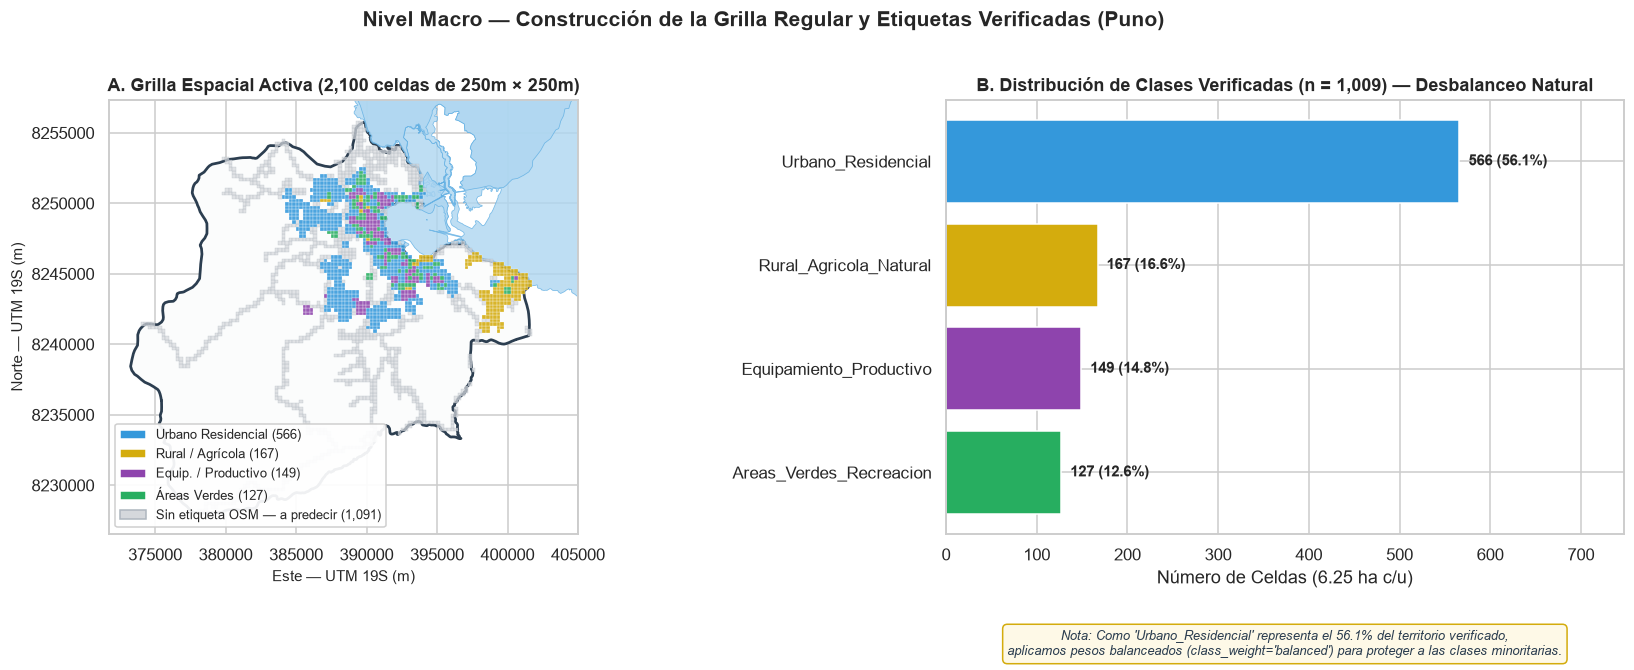

Figura guardada en: figures/03_grilla_espacial_macro.png


In [4]:
# Visualización de la Grilla Espacial 250m×250m y Distribución de Clases Verificadas (300 DPI)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={'width_ratios': [1.15, 1]})

colores_zonas_map = {
    'Urbano_Residencial': '#3498db',
    'Rural_Agricola_Natural': '#d4ac0d',
    'Equipamiento_Productivo': '#8e44ad',
    'Areas_Verdes_Recreacion': '#27ae60'
}

# Panel A: Mapa de la grilla espacial 250m x 250m en el Distrito de Puno
boundary_utm.plot(ax=ax1, color='#fbfcfc', edgecolor='#2c3e50', linewidth=1.8, zorder=1)
water_utm.plot(ax=ax1, color='#aed6f1', edgecolor='#5dade2', linewidth=0.5, alpha=0.8, zorder=2)

# Celdas sin etiqueta (a predecir) en gris suave
grid_activas[grid_activas['zona_macro'].isna()].plot(
    ax=ax1, color='#d5d8dc', edgecolor='#aeb6bf', linewidth=0.25, alpha=0.7, zorder=3
)
# Celdas verificadas coloreadas por zona real
for z_name, z_col in colores_zonas_map.items():
    grid_activas[grid_activas['zona_macro'] == z_name].plot(
        ax=ax1, color=z_col, edgecolor='white', linewidth=0.2, alpha=0.88, zorder=4
    )

bminx, bminy, bmaxx, bmaxy = boundary_utm.total_bounds
ax1.set_xlim(bminx - 1500, bmaxx + 3500)
ax1.set_ylim(bminy - 1500, bmaxy + 1500)
ax1.set_title("A. Grilla Espacial Activa (2,100 celdas de 250m × 250m)")
ax1.set_xlabel("Este — UTM 19S (m)")
ax1.set_ylabel("Norte — UTM 19S (m)")
ax1.ticklabel_format(style='plain', axis='both')

handles_g = [
    mpatches.Patch(facecolor='#3498db', label='Urbano Residencial (566)'),
    mpatches.Patch(facecolor='#d4ac0d', label='Rural / Agrícola (167)'),
    mpatches.Patch(facecolor='#8e44ad', label='Equip. / Productivo (149)'),
    mpatches.Patch(facecolor='#27ae60', label='Áreas Verdes (127)'),
    mpatches.Patch(facecolor='#d5d8dc', edgecolor='#aeb6bf', label='Sin etiqueta OSM — a predecir (1,091)')
]
ax1.legend(handles=handles_g, loc='lower left', fontsize=8.3, frameon=True, facecolor='white', framealpha=0.93)

# Panel B: Distribución y desbalanceo de las 1,009 celdas verificadas
orden_zonas = ['Urbano_Residencial', 'Rural_Agricola_Natural', 'Equipamiento_Productivo', 'Areas_Verdes_Recreacion']
counts_z = grid_activas['zona_macro'].value_counts().reindex(orden_zonas)
tot_z = counts_z.sum()
bars = ax2.barh(orden_zonas[::-1], counts_z.values[::-1],
                color=[colores_zonas_map[z] for z in orden_zonas[::-1]], edgecolor='white')
ax2.set_title("B. Distribución de Clases Verificadas (n = 1,009) — Desbalanceo Natural")
ax2.set_xlabel("Número de Celdas (6.25 ha c/u)")
ax2.set_xlim(0, counts_z.max() * 1.32)
for b in bars:
    w = int(b.get_width())
    ax2.annotate(f"{w} ({w/tot_z*100:.1f}%)", (w + 10, b.get_y() + b.get_height()/2),
                 va='center', fontsize=9.8, fontweight='bold')

ax2.text(
    0.5, -0.22,
    "Nota: Como 'Urbano_Residencial' representa el 56.1% del territorio verificado,\naplicamos pesos balanceados (class_weight='balanced') para proteger a las clases minoritarias.",
    transform=ax2.transAxes, ha='center', va='top', fontsize=8.8, style='italic', color='#2c3e50',
    bbox=dict(boxstyle='round,pad=0.35', facecolor='#fef9e7', edgecolor='#d4ac0d')
)

plt.suptitle("Nivel Macro — Construcción de la Grilla Regular y Etiquetas Verificadas (Puno)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "03_grilla_espacial_macro.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/03_grilla_espacial_macro.png")

## 3. Ingeniería de 17 Variables Espaciales ($X$): Puente Micro $\rightarrow$ Macro + `KD-Tree`

Construimos las **17 variables predictoras** agregando **4 fuentes 100% independientes** de las etiquetas:
1. **Agregación del Nivel Micro (Paso 2 — `puno_buildings_clasificados.geojson`):**
   * `num_edificios`, `pct_area_construida`, `edificios_residenciales`, `edificios_comerciales`, `edificios_institucionales`.
2. **Morfología y Densidad Vial (`puno_roads.geojson`):**
   * `longitud_vias_m`, `num_tramos_via`, `pct_vias_arteriales`, `pct_vias_rurales_peat`, `dist_via_principal_m`.
3. **Servicios Puntuales y Transporte (`puno_pois` + `puno_transport`) usando `cKDTree` ($O(\log N)$):**
   * `num_pois_celda`, `num_pois_500m`, `dist_poi_cercano_m`, `dist_transporte_m`.
4. **Contexto Geográfico e Hídrico de Puno (`puno_water_a` + `puno_waterways`):**
   * `dist_plaza_armas_m`, `dist_lago_agua_m`, `dist_quebrada_rio_m`.

In [5]:
# --- 1. AGREGACIÓN DEL NIVEL MICRO (EDIFICACIONES CLASIFICADAS DEL PASO 2) ---
b_cent = b_micro_utm[['clase_final', 'area_m2', 'geometry']].copy()
b_cent['geometry'] = b_cent.geometry.centroid
j_build = gpd.sjoin(grid_activas[['cell_id', 'geometry']], b_cent, how='left', predicate='contains').reset_index(drop=True)

agg_b = j_build.groupby('cell_id').agg(
    num_edificios=('area_m2', 'count'),
    area_construida_m2=('area_m2', 'sum')
).fillna(0)
agg_b['pct_area_construida'] = (agg_b['area_construida_m2'] / CELL_AREA) * 100.0

ct_micro = pd.crosstab(j_build['cell_id'], j_build['clase_final'])
for col, nombre_col in [
    ('Residencial', 'edificios_residenciales'),
    ('Comercial_Servicios', 'edificios_comerciales'),
    ('Institucional', 'edificios_institucionales')
]:
    grid_activas[nombre_col] = grid_activas['cell_id'].map(ct_micro[col] if col in ct_micro else pd.Series()).fillna(0)

grid_activas['num_edificios'] = grid_activas['cell_id'].map(agg_b['num_edificios']).fillna(0)
grid_activas['pct_area_construida'] = grid_activas['cell_id'].map(agg_b['pct_area_construida']).fillna(0)

# --- 2. MORFOLOGÍA Y DENSIDAD DE LA RED VIAL ---
vias_arteriales_set = {'trunk', 'primary', 'primary_link', 'secondary', 'secondary_link', 'tertiary', 'tertiary_link'}
vias_rurales_set = {'track', 'path', 'footway', 'steps', 'pedestrian'}

roads_clip = gpd.overlay(
    roads_utm[['fclass', 'geometry']],
    grid_activas[['cell_id', 'geometry']],
    how='intersection',
    keep_geom_type=False
)
roads_clip['len_m'] = roads_clip.geometry.length
roads_clip['len_arterial'] = np.where(roads_clip['fclass'].isin(vias_arteriales_set), roads_clip['len_m'], 0.0)
roads_clip['len_rural'] = np.where(roads_clip['fclass'].isin(vias_rurales_set), roads_clip['len_m'], 0.0)

agg_roads = roads_clip.groupby('cell_id').agg(
    longitud_vias_m=('len_m', 'sum'),
    num_tramos_via=('len_m', 'count'),
    len_arterial=('len_arterial', 'sum'),
    len_rural=('len_rural', 'sum')
)
agg_roads['pct_vias_arteriales'] = agg_roads['len_arterial'] / (agg_roads['longitud_vias_m'] + 1e-6)
agg_roads['pct_vias_rurales_peat'] = agg_roads['len_rural'] / (agg_roads['longitud_vias_m'] + 1e-6)

for col in ['longitud_vias_m', 'num_tramos_via', 'pct_vias_arteriales', 'pct_vias_rurales_peat']:
    grid_activas[col] = grid_activas['cell_id'].map(agg_roads[col]).fillna(0)

centroides_grid = gpd.GeoDataFrame({'cell_id': grid_activas['cell_id'], 'geometry': grid_activas.geometry.centroid}, crs=CRS_METRICO)
vias_principales = roads_utm[roads_utm['fclass'].isin(vias_arteriales_set)][['geometry']]
near_art = gpd.sjoin_nearest(centroides_grid, vias_principales, how='left', distance_col='dist_via_principal_m').drop_duplicates('cell_id')
grid_activas['dist_via_principal_m'] = grid_activas['cell_id'].map(near_art.set_index('cell_id')['dist_via_principal_m'])

# --- 3. SERVICIOS (POIs) Y TRANSPORTE USANDO cKDTree ---
coords_grid = np.column_stack([centroides_grid.geometry.x, centroides_grid.geometry.y])

j_pois = gpd.sjoin(grid_activas[['cell_id', 'geometry']], pois_utm[['geometry']], how='left', predicate='contains').reset_index(drop=True)
grid_activas['num_pois_celda'] = grid_activas['cell_id'].map(j_pois.groupby('cell_id')['index_right'].count()).fillna(0)

coords_pois = np.column_stack([pois_utm.geometry.x, pois_utm.geometry.y])
tree_pois = cKDTree(coords_pois)
dist_poi, _ = tree_pois.query(coords_grid, k=1)
grid_activas['dist_poi_cercano_m'] = dist_poi
grid_activas['num_pois_500m'] = [len(idx) for idx in tree_pois.query_ball_point(coords_grid, r=500.0)]

coords_transp = np.column_stack([transport_utm.geometry.x, transport_utm.geometry.y])
tree_transp = cKDTree(coords_transp)
dist_transp, _ = tree_transp.query(coords_grid, k=1)
grid_activas['dist_transporte_m'] = dist_transp

# --- 4. CONTEXTO GEOGRÁFICO E HÍDRICO DE PUNO ---
grid_activas['dist_plaza_armas_m'] = centroides_grid.geometry.distance(plaza_armas_utm)
agua_union = water_utm.geometry.union_all()
rios_union = waterways_utm.geometry.union_all()
grid_activas['dist_lago_agua_m'] = centroides_grid.geometry.distance(agua_union)
grid_activas['dist_quebrada_rio_m'] = centroides_grid.geometry.distance(rios_union)

FEATURES_MACRO = [
    'num_edificios', 'pct_area_construida',
    'edificios_residenciales', 'edificios_comerciales', 'edificios_institucionales',
    'longitud_vias_m', 'num_tramos_via', 'pct_vias_arteriales', 'pct_vias_rurales_peat', 'dist_via_principal_m',
    'num_pois_celda', 'num_pois_500m', 'dist_poi_cercano_m', 'dist_transporte_m',
    'dist_plaza_armas_m', 'dist_lago_agua_m', 'dist_quebrada_rio_m'
]

grid_activas[['cell_id', 'zona_macro'] + FEATURES_MACRO].to_csv(
    DIR_DATA_PUNO / "dataset_macro_zonificacion.csv", index=False
)
print(f"Dataset Macro guardado en data_puno/dataset_macro_zonificacion.csv ({len(FEATURES_MACRO)} features)")
display(grid_activas.dropna(subset=['zona_macro']).groupby('zona_macro')[FEATURES_MACRO].median().round(2).T)

Dataset Macro guardado en data_puno/dataset_macro_zonificacion.csv (17 features)


zona_macro,Areas_Verdes_Recreacion,Equipamiento_Productivo,Rural_Agricola_Natural,Urbano_Residencial
num_edificios,0.00,0.00,0.00,0.00
pct_area_construida,0.00,0.00,0.00,0.00
edificios_residenciales,0.00,0.00,0.00,0.00
edificios_comerciales,0.00,0.00,0.00,0.00
edificios_institucionales,0.00,0.00,0.00,0.00
longitud_vias_m,1392.70,1441.58,202.30,622.33
num_tramos_via,14.00,14.00,1.00,6.00
pct_vias_arteriales,0.03,0.10,0.00,0.00
pct_vias_rurales_peat,0.00,0.00,0.00,0.00
dist_via_principal_m,145.23,113.70,503.81,309.96


## 4. Validación (`80% Train / 20% Test` + `5-Fold CV`) y Matemática del Balanceo de Clases

Al igual que en el Nivel Micro, separamos rigurosamente la **Fase de Evaluación** (sobre las `1,009` celdas verificadas: `80% Train = 807`, `20% Test = 202` como examen final) de la **Fase de Imputación** (las `1,091` celdas sin etiqueta en OSM que se predicen al final).

### ¿Cómo compensamos matemáticamente el desbalanceo de clases?
Como `Urbano_Residencial` abarca el `56.1%` del suelo verificado frente a `12.6%` de `Areas_Verdes_Recreacion`, asignamos a cada clase $k$ un **peso inversamente proporcional a su frecuencia** (`class_weight='balanced'` / `compute_sample_weight('balanced')`):
$$w_k = \frac{N}{K \cdot N_k}$$
donde $N = 807$ es el tamaño de entrenamiento, $K = 4$ clases y $N_k$ es la cantidad de celdas de la clase $k$. Así, equivocarse en una celda minoritaria (`Áreas Verdes`) penaliza ~4.4 veces más que equivocarse en `Urbano_Residencial`, obligando a los 4 modelos a aprender bien **todas** las zonas. Por la misma razón evaluamos con **F1-Score Macro** y **Balanced Accuracy** (promedio equitativo del Recall por clase).

Mapeo numérico de clases Macro: {0: 'Areas_Verdes_Recreacion', 1: 'Equipamiento_Productivo', 2: 'Rural_Agricola_Natural', 3: 'Urbano_Residencial'}
Total verificadas: 1009  ->  Train (80%): 807  |  Test (20%): 202
Pesos balanceados w_k = N / (K * N_k): {'Areas_Verdes_Recreacion': np.float64(1.978), 'Equipamiento_Productivo': np.float64(1.695), 'Rural_Agricola_Natural': np.float64(1.517), 'Urbano_Residencial': np.float64(0.445)}


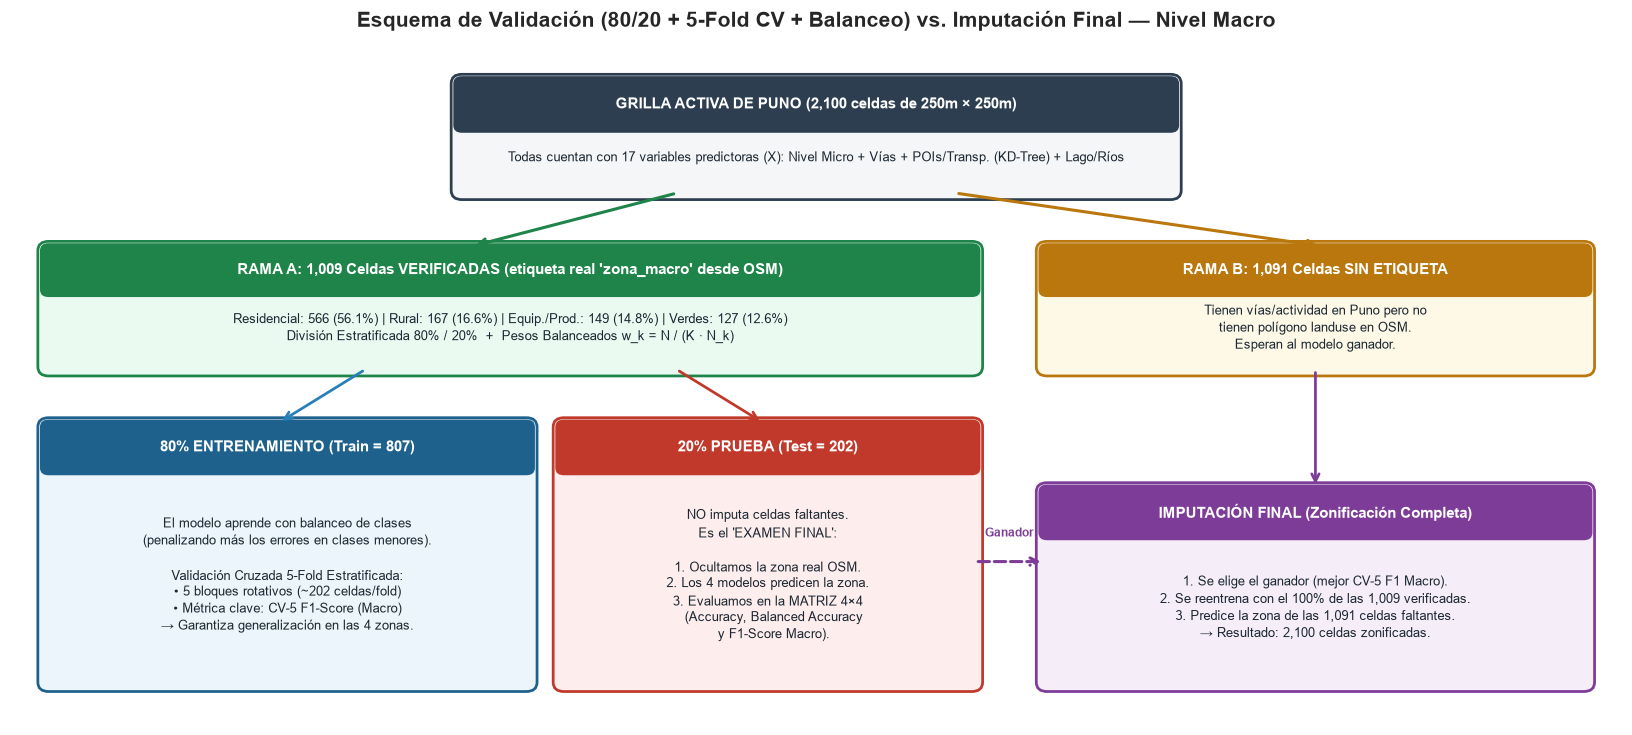

Figura guardada en: figures/03_flujo_validacion_macro.png


In [6]:
df_macro_labeled = grid_activas.dropna(subset=['zona_macro']).copy()
X = df_macro_labeled[FEATURES_MACRO].copy()
le = LabelEncoder()
y = le.fit_transform(df_macro_labeled['zona_macro'])
clases_nombres = list(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Mapeo numérico de clases Macro:", dict(enumerate(clases_nombres)))
print(f"Total verificadas: {len(X)}  ->  Train (80%): {len(X_train)}  |  Test (20%): {len(X_test)}")

# Mostrar pesos matemáticos exactos aplicados a cada clase en Train
pesos_clase = {clases_nombres[k]: round(len(y_train) / (4 * (y_train == k).sum()), 3) for k in range(4)}
print("Pesos balanceados w_k = N / (K * N_k):", pesos_clase)

# --- DIAGRAMA VISUAL DEL FLUJO DE VALIDACIÓN E IMPUTACIÓN — NIVEL MACRO (300 DPI) ---
fig, ax = plt.subplots(figsize=(15, 6.8))
ax.set_xlim(0, 15)
ax.set_ylim(0, 7.2)
ax.axis('off')

def caja(x, y, w, h, titulo, texto, bg, edge, title_color='white', hdr_h=0.55):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1", facecolor=bg, edgecolor=edge, linewidth=1.8))
    ax.add_patch(FancyBboxPatch((x, y + h - hdr_h), w, hdr_h, boxstyle="round,pad=0.08", facecolor=edge, edgecolor='none'))
    ax.text(x + w/2, y + h - hdr_h/2, titulo, color=title_color, fontsize=9.8, fontweight='bold', ha='center', va='center')
    ax.text(x + w/2, y + (h - hdr_h)/2, texto, color='#1c2833', fontsize=8.8, ha='center', va='center', linespacing=1.35)

caja(4.2, 5.75, 6.6, 1.15, "GRILLA ACTIVA DE PUNO (2,100 celdas de 250m × 250m)",
     "Todas cuentan con 17 variables predictoras (X): Nivel Micro + Vías + POIs/Transp. (KD-Tree) + Lago/Ríos",
     '#f4f6f7', '#2c3e50', hdr_h=0.45)

ax.annotate('', xy=(4.3, 5.15), xytext=(6.2, 5.72), arrowprops=dict(arrowstyle='->', lw=2.0, color='#1e8449'))
ax.annotate('', xy=(12.2, 5.15), xytext=(8.8, 5.72), arrowprops=dict(arrowstyle='->', lw=2.0, color='#b9770e'))

caja(0.35, 3.85, 8.6, 1.25, "RAMA A: 1,009 Celdas VERIFICADAS (etiqueta real 'zona_macro' desde OSM)",
     "Residencial: 566 (56.1%) | Rural: 167 (16.6%) | Equip./Prod.: 149 (14.8%) | Verdes: 127 (12.6%)\nDivisión Estratificada 80% / 20%  +  Pesos Balanceados w_k = N / (K · N_k)",
     '#eafaf1', '#1e8449', hdr_h=0.42)

ax.annotate('', xy=(2.5, 3.25), xytext=(3.3, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#2980b9'))
ax.annotate('', xy=(7.0, 3.25), xytext=(6.2, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#c0392b'))

caja(0.35, 0.45, 4.45, 2.75, "80% ENTRENAMIENTO (Train = 807)",
     "El modelo aprende con balanceo de clases\n(penalizando más los errores en clases menores).\n\nValidación Cruzada 5-Fold Estratificada:\n• 5 bloques rotativos (~202 celdas/fold)\n• Métrica clave: CV-5 F1-Score (Macro)\n→ Garantiza generalización en las 4 zonas.",
     '#ebf5fb', '#1f618d', hdr_h=0.44)

caja(5.15, 0.45, 3.8, 2.75, "20% PRUEBA (Test = 202)",
     "NO imputa celdas faltantes.\nEs el 'EXAMEN FINAL':\n\n1. Ocultamos la zona real OSM.\n2. Los 4 modelos predicen la zona.\n3. Evaluamos en la MATRIZ 4×4\n   (Accuracy, Balanced Accuracy\n   y F1-Score Macro).",
     '#fdedec', '#c0392b', hdr_h=0.44)

caja(9.65, 3.85, 5.0, 1.25, "RAMA B: 1,091 Celdas SIN ETIQUETA",
     "Tienen vías/actividad en Puno pero no\ntienen polígono landuse en OSM.\nEsperan al modelo ganador.",
     '#fef9e7', '#b9770e', hdr_h=0.42)

ax.annotate('', xy=(12.15, 2.55), xytext=(12.15, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#7d3c98'))
ax.annotate('', xy=(9.62, 1.75), xytext=(8.98, 1.75), arrowprops=dict(arrowstyle='->', lw=2.0, color='#7d3c98', ls='--'))
ax.text(9.30, 2.02, "Ganador", fontsize=8, fontweight='bold', color='#7d3c98', ha='center')

caja(9.65, 0.45, 5.0, 2.05, "IMPUTACIÓN FINAL (Zonificación Completa)",
     "1. Se elige el ganador (mejor CV-5 F1 Macro).\n2. Se reentrena con el 100% de las 1,009 verificadas.\n3. Predice la zona de las 1,091 celdas faltantes.\n→ Resultado: 2,100 celdas zonificadas.",
     '#f5eef8', '#7d3c98', hdr_h=0.44)

plt.suptitle("Esquema de Validación (80/20 + 5-Fold CV + Balanceo) vs. Imputación Final — Nivel Macro",
             fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "03_flujo_validacion_macro.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/03_flujo_validacion_macro.png")

## 5. Entrenamiento y Evaluación de los 4 Modelos Obligatorios (Nivel Macro)

Aplicamos exactamente los mismos **4 paradigmas matemáticos** fundamentados en el Paso 2 (`DecisionTree Gini/Entropía`, `Random Forest`, `XGBoost` y `LightGBM`), adaptados a la mayor complejidad espacial del Nivel Macro (`1,009` celdas, `17` features, `4` clases balanceadas).

### Paso 5.1: Experimento de Poda (`max_depth`) — Gini vs. Entropía

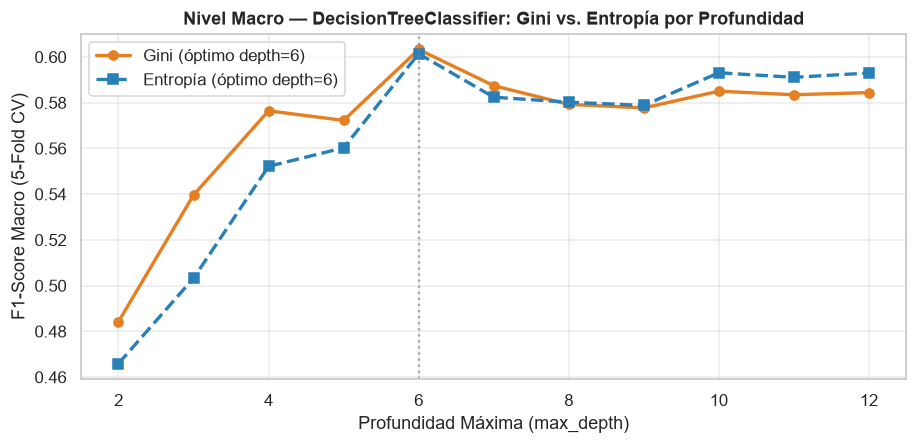

In [7]:
profundidades = range(2, 13)
scores_gini, scores_entropy = [], []

for d in profundidades:
    f1_g, f1_e = [], []
    for tr_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train[tr_idx], y_train[val_idx]
        dt_g = DecisionTreeClassifier(criterion='gini', max_depth=d, min_samples_leaf=5, class_weight='balanced', random_state=42)
        dt_e = DecisionTreeClassifier(criterion='entropy', max_depth=d, min_samples_leaf=5, class_weight='balanced', random_state=42)
        dt_g.fit(X_tr, y_tr)
        dt_e.fit(X_tr, y_tr)
        f1_g.append(f1_score(y_val, dt_g.predict(X_val), average='macro'))
        f1_e.append(f1_score(y_val, dt_e.predict(X_val), average='macro'))
    scores_gini.append(np.mean(f1_g))
    scores_entropy.append(np.mean(f1_e))

mejor_d_gini = list(profundidades)[int(np.argmax(scores_gini))]
mejor_d_entropy = list(profundidades)[int(np.argmax(scores_entropy))]

plt.figure(figsize=(8.5, 4.2))
plt.plot(profundidades, scores_gini, marker='o', linewidth=2.2, color='#e67e22', label=f'Gini (óptimo depth={mejor_d_gini})')
plt.plot(profundidades, scores_entropy, marker='s', linewidth=2.2, linestyle='--', color='#2980b9', label=f'Entropía (óptimo depth={mejor_d_entropy})')
plt.axvline(mejor_d_gini, color='#7f8c8d', linestyle=':', alpha=0.7)
plt.title("Nivel Macro — DecisionTreeClassifier: Gini vs. Entropía por Profundidad", fontweight='bold')
plt.xlabel("Profundidad Máxima (max_depth)")
plt.ylabel("F1-Score Macro (5-Fold CV)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

### Paso 5.2: Comparativa Completa de los 4 Modelos (5 configuraciones)

In [8]:
def crear_modelos():
    return {
        'DecisionTree (Gini)': DecisionTreeClassifier(
            criterion='gini', max_depth=mejor_d_gini, min_samples_leaf=5,
            class_weight='balanced', random_state=42
        ),
        'DecisionTree (Entropía)': DecisionTreeClassifier(
            criterion='entropy', max_depth=mejor_d_entropy, min_samples_leaf=5,
            class_weight='balanced', random_state=42
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=250, max_depth=12, min_samples_leaf=3,
            class_weight='balanced', random_state=42, n_jobs=-1
        ),
        'XGBoost': XGBClassifier(
            n_estimators=200, max_depth=5, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42
        ),
        'LightGBM': LGBMClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.05,
            num_leaves=25, min_child_samples=15, class_weight='balanced', random_state=42, verbose=-1
        )
    }

resultados_macro = []
predicciones_test = {}
modelos_entrenados = {}

for nombre, modelo in crear_modelos().items():
    cv_accs, cv_f1s = [], []
    for tr_idx, val_idx in cv.split(X, y):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y[tr_idx], y[val_idx]
        m_cv = crear_modelos()[nombre]
        if nombre == 'XGBoost':
            sw = compute_sample_weight('balanced', y_tr)
            m_cv.fit(X_tr, y_tr, sample_weight=sw)
        else:
            m_cv.fit(X_tr, y_tr)
        p_val = m_cv.predict(X_val)
        cv_accs.append(accuracy_score(y_val, p_val))
        cv_f1s.append(f1_score(y_val, p_val, average='macro'))

    t0 = time.perf_counter()
    if nombre == 'XGBoost':
        sw_train = compute_sample_weight('balanced', y_train)
        modelo.fit(X_train, y_train, sample_weight=sw_train)
    else:
        modelo.fit(X_train, y_train)
    tiempo_ms = (time.perf_counter() - t0) * 1000

    y_pred = modelo.predict(X_test)
    predicciones_test[nombre] = y_pred
    modelos_entrenados[nombre] = modelo

    resultados_macro.append({
        'Modelo': nombre,
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Test Balanced Acc': balanced_accuracy_score(y_test, y_pred),
        'Test Precision (Macro)': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Test Recall (Macro)': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Test F1 (Macro)': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'CV-5 Accuracy': np.mean(cv_accs),
        'CV-5 F1 (Macro)': np.mean(cv_f1s),
        'Tiempo Train (ms)': tiempo_ms
    })

df_resultados_macro = pd.DataFrame(resultados_macro).sort_values(by='CV-5 F1 (Macro)', ascending=False)
df_resultados_macro.to_csv(DIR_DATA_PUNO / "resultados_macro_modelos.csv", index=False)
display(df_resultados_macro.round(4))

,Modelo,Test Accuracy,Test Balanced Acc,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro),CV-5 Accuracy,CV-5 F1 (Macro),Tiempo Train (ms)
2,Random Forest,0.7426,0.7023,0.6792,0.7023,0.6803,0.7681,0.6980,802.0942
3,XGBoost,0.7772,0.7189,0.7065,0.7189,0.7120,0.7760,0.6977,961.5182
4,LightGBM,0.7574,0.6728,0.6619,0.6728,0.6670,0.7691,0.6767,348.9037
0,DecisionTree (Gini),0.6535,0.6221,0.6039,0.6221,0.5996,0.6809,0.6318,6.6644
1,DecisionTree (Entropía),0.6634,0.6205,0.5806,0.6205,0.5841,0.6671,0.5999,7.9195


## 6. Visualización Completa de los Árboles en los 4 Modelos (Sin Recortes `(...)`)

Al igual que en el Nivel Micro, graficamos **cada árbol por separado y de forma 100% completa hasta todas sus hojas terminales**:
* **6.1. `DecisionTree (Gini)` completo** (profundidad 6, 27 hojas).
* **6.2. `DecisionTree (Entropía)` completo** (profundidad 6, 28 hojas).
* **6.3. `Random Forest` completo (Árbol #1 y Árbol #250):** mostramos el primer y el último árbol de los 250 árboles paralelos del bosque ganador.
* **6.4. `XGBoost` completo (Ronda 1 y Ronda Final #200):** estructura real *level-wise* con todas sus hojas $w^*$.
* **6.5. `LightGBM` completo (Ronda 2 y Ronda Final #200):** estructura real *leaf-wise* con todas sus hojas $w^*$.

### 6.1. Modelo 1A — `DecisionTreeClassifier` (Criterio GINI — Árbol Completo)

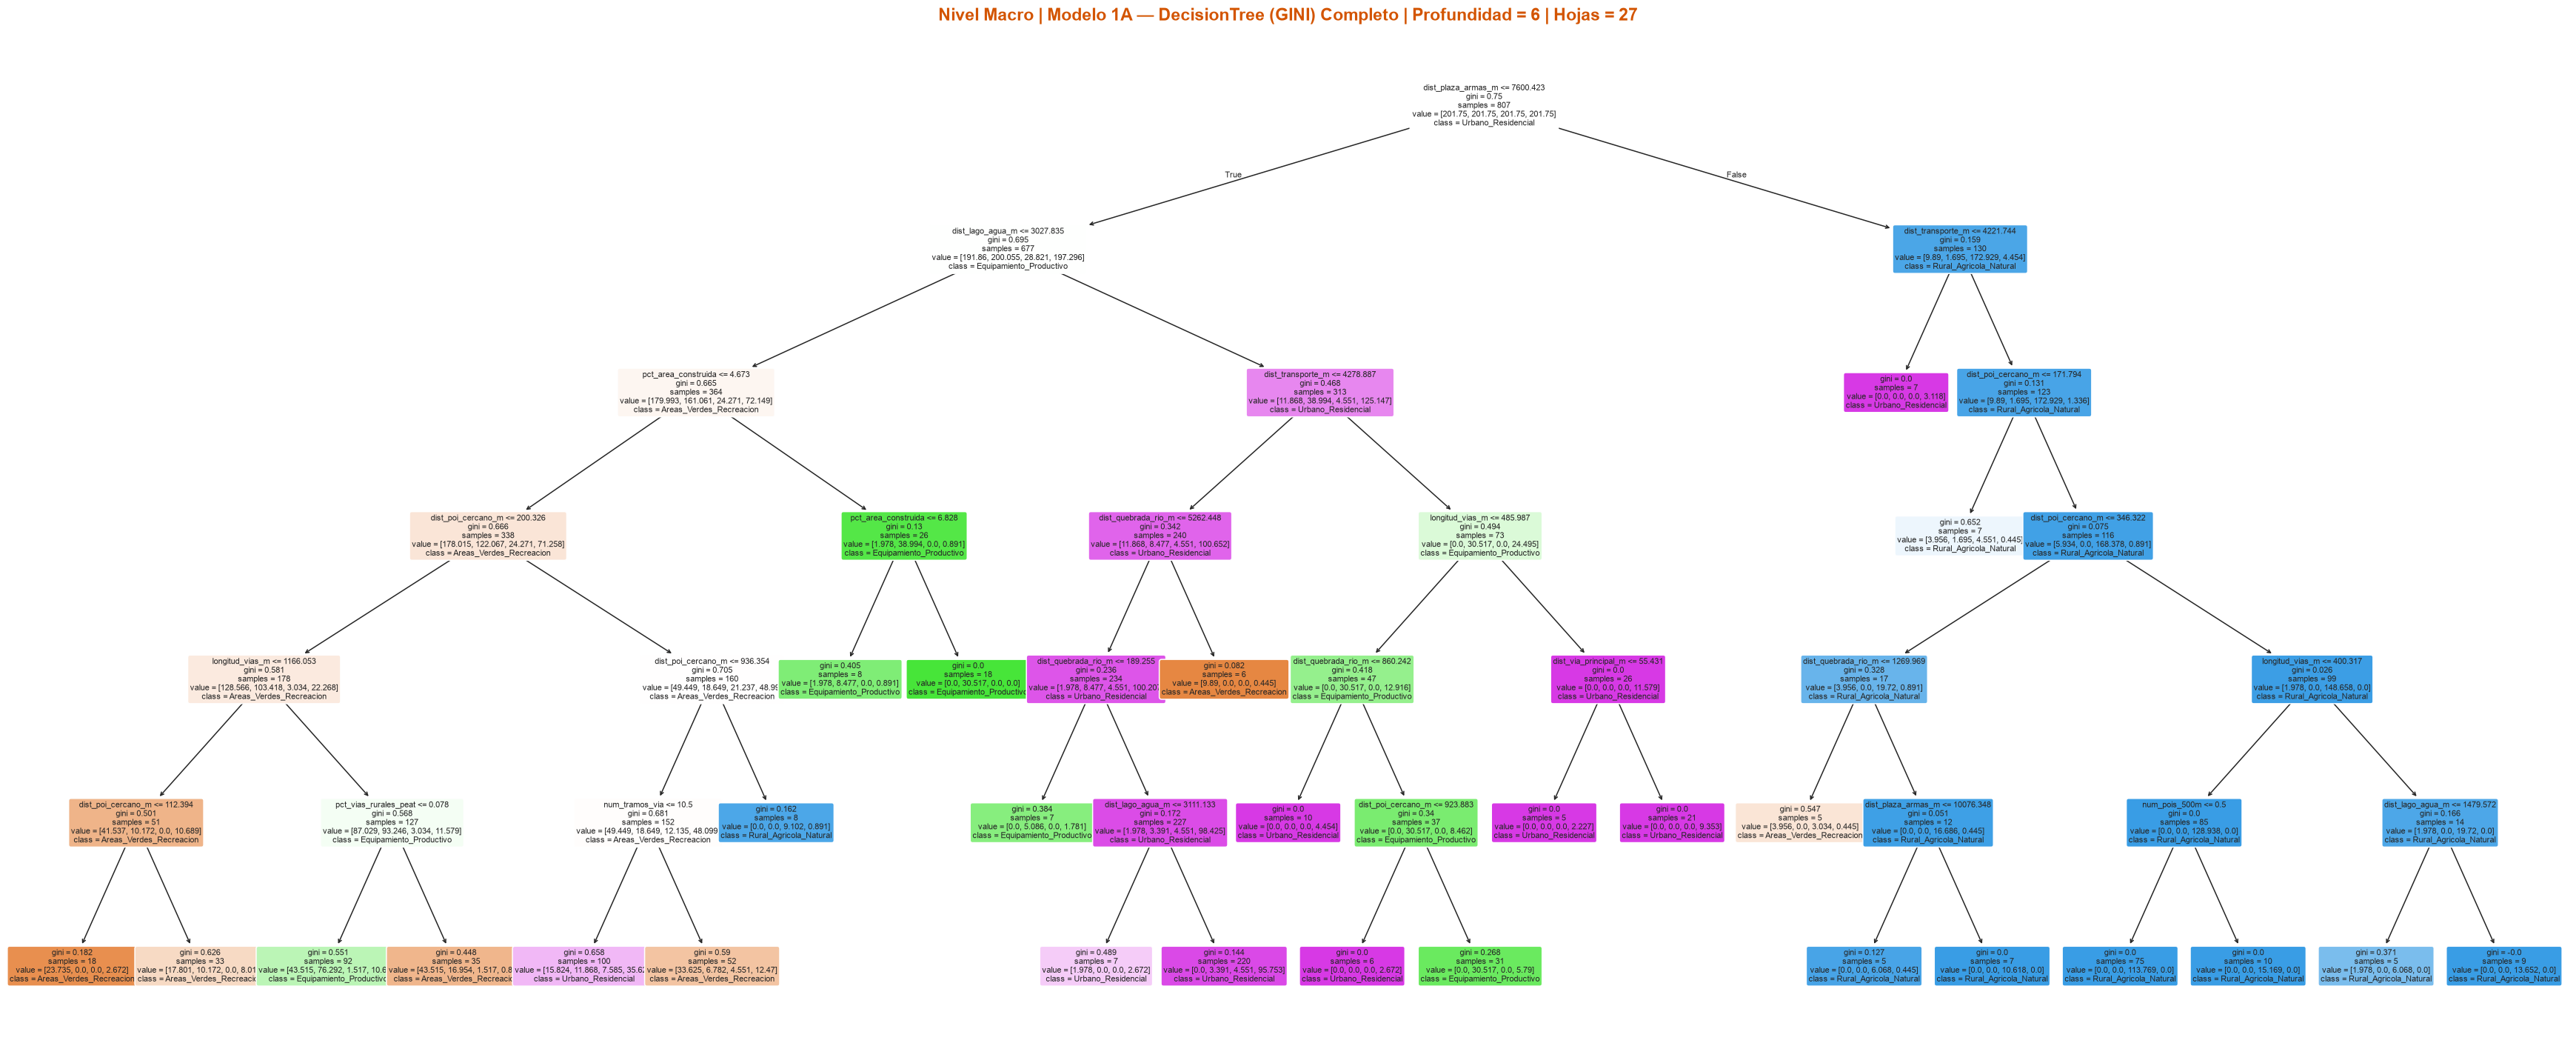

Figura guardada en: figures/03_arbol_gini_completo.png


In [9]:
dt_g = modelos_entrenados['DecisionTree (Gini)']
fig, ax = plt.subplots(figsize=(32, 13))
plot_tree(
    dt_g,
    feature_names=FEATURES_MACRO,
    class_names=clases_nombres,
    filled=True, rounded=True, fontsize=7, ax=ax
)
ax.set_title(
    f"Nivel Macro | Modelo 1A — DecisionTree (GINI) Completo | Profundidad = {dt_g.get_depth()} | Hojas = {dt_g.get_n_leaves()}",
    fontsize=15, fontweight='bold', color='#d35400', pad=12
)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "03_arbol_gini_completo.png", bbox_inches='tight', dpi=250)
plt.show()
print("Figura guardada en: figures/03_arbol_gini_completo.png")

### 6.2. Modelo 1B — `DecisionTreeClassifier` (Criterio ENTROPÍA — Árbol Completo)

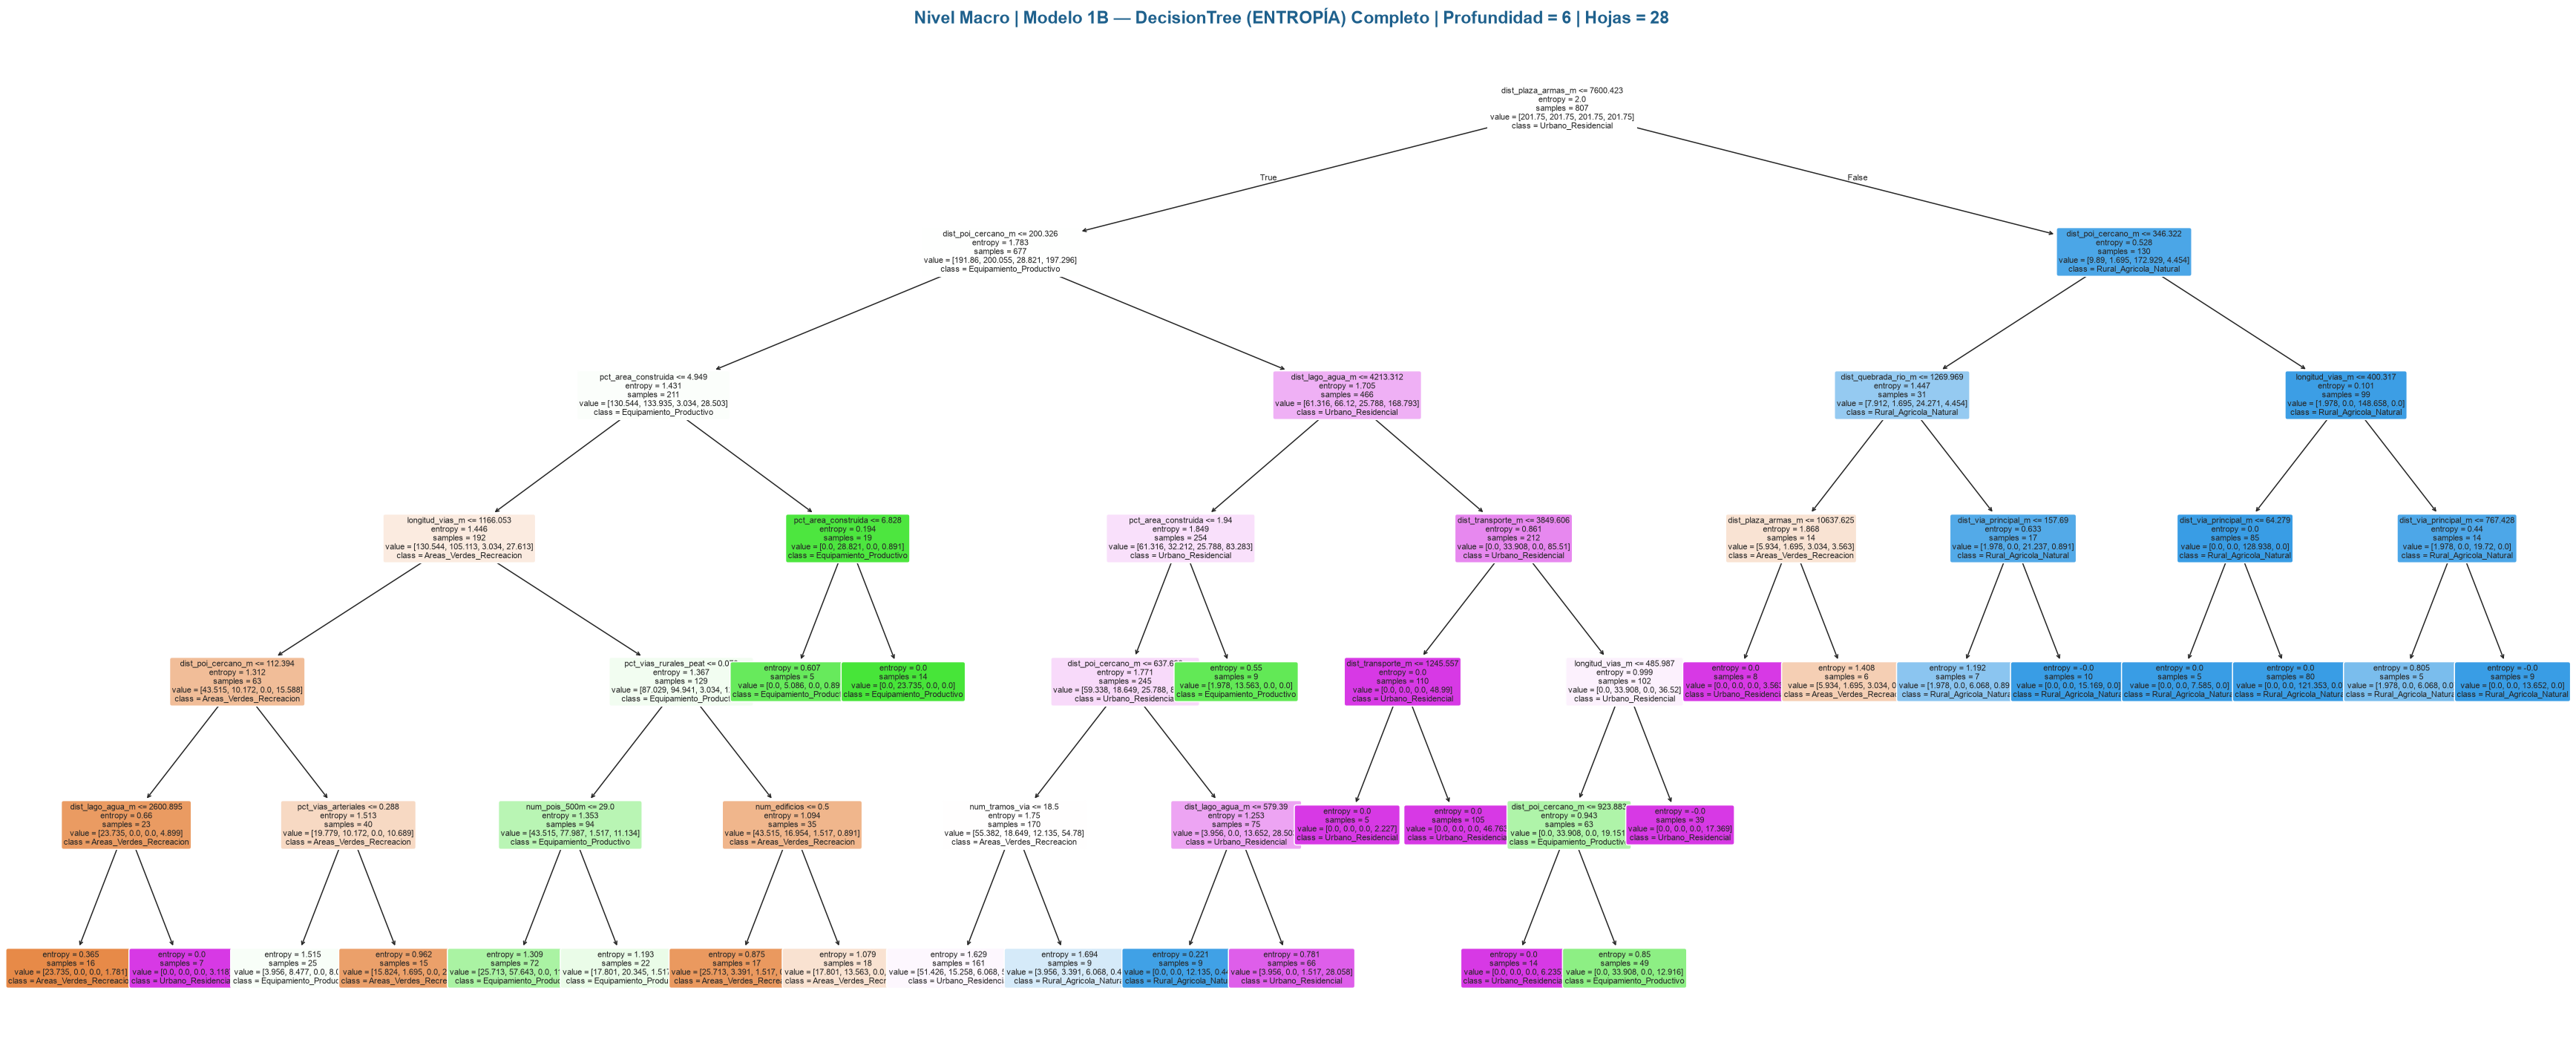

Figura guardada en: figures/03_arbol_entropia_completo.png


In [10]:
dt_e = modelos_entrenados['DecisionTree (Entropía)']
fig, ax = plt.subplots(figsize=(32, 13))
plot_tree(
    dt_e,
    feature_names=FEATURES_MACRO,
    class_names=clases_nombres,
    filled=True, rounded=True, fontsize=7, ax=ax
)
ax.set_title(
    f"Nivel Macro | Modelo 1B — DecisionTree (ENTROPÍA) Completo | Profundidad = {dt_e.get_depth()} | Hojas = {dt_e.get_n_leaves()}",
    fontsize=15, fontweight='bold', color='#1f618d', pad=12
)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "03_arbol_entropia_completo.png", bbox_inches='tight', dpi=250)
plt.show()
print("Figura guardada en: figures/03_arbol_entropia_completo.png")

### 6.3. Modelo 2 — `RandomForestClassifier` (*Bagging*): Árbol #1 y Árbol #250 Completos

En el Nivel Macro, Random Forest (ganador por `CV-5 F1 Macro = 0.6980`) entrena **250 árboles independientes en paralelo** con `max_depth=12`. Mostramos el **Árbol #1** y el **Árbol #250** completos sin recortar ninguna hoja *(al tener ~75 hojas, abrir la imagen PNG en `figures/` permite hacer zoom nítido sobre cada nodo)*.

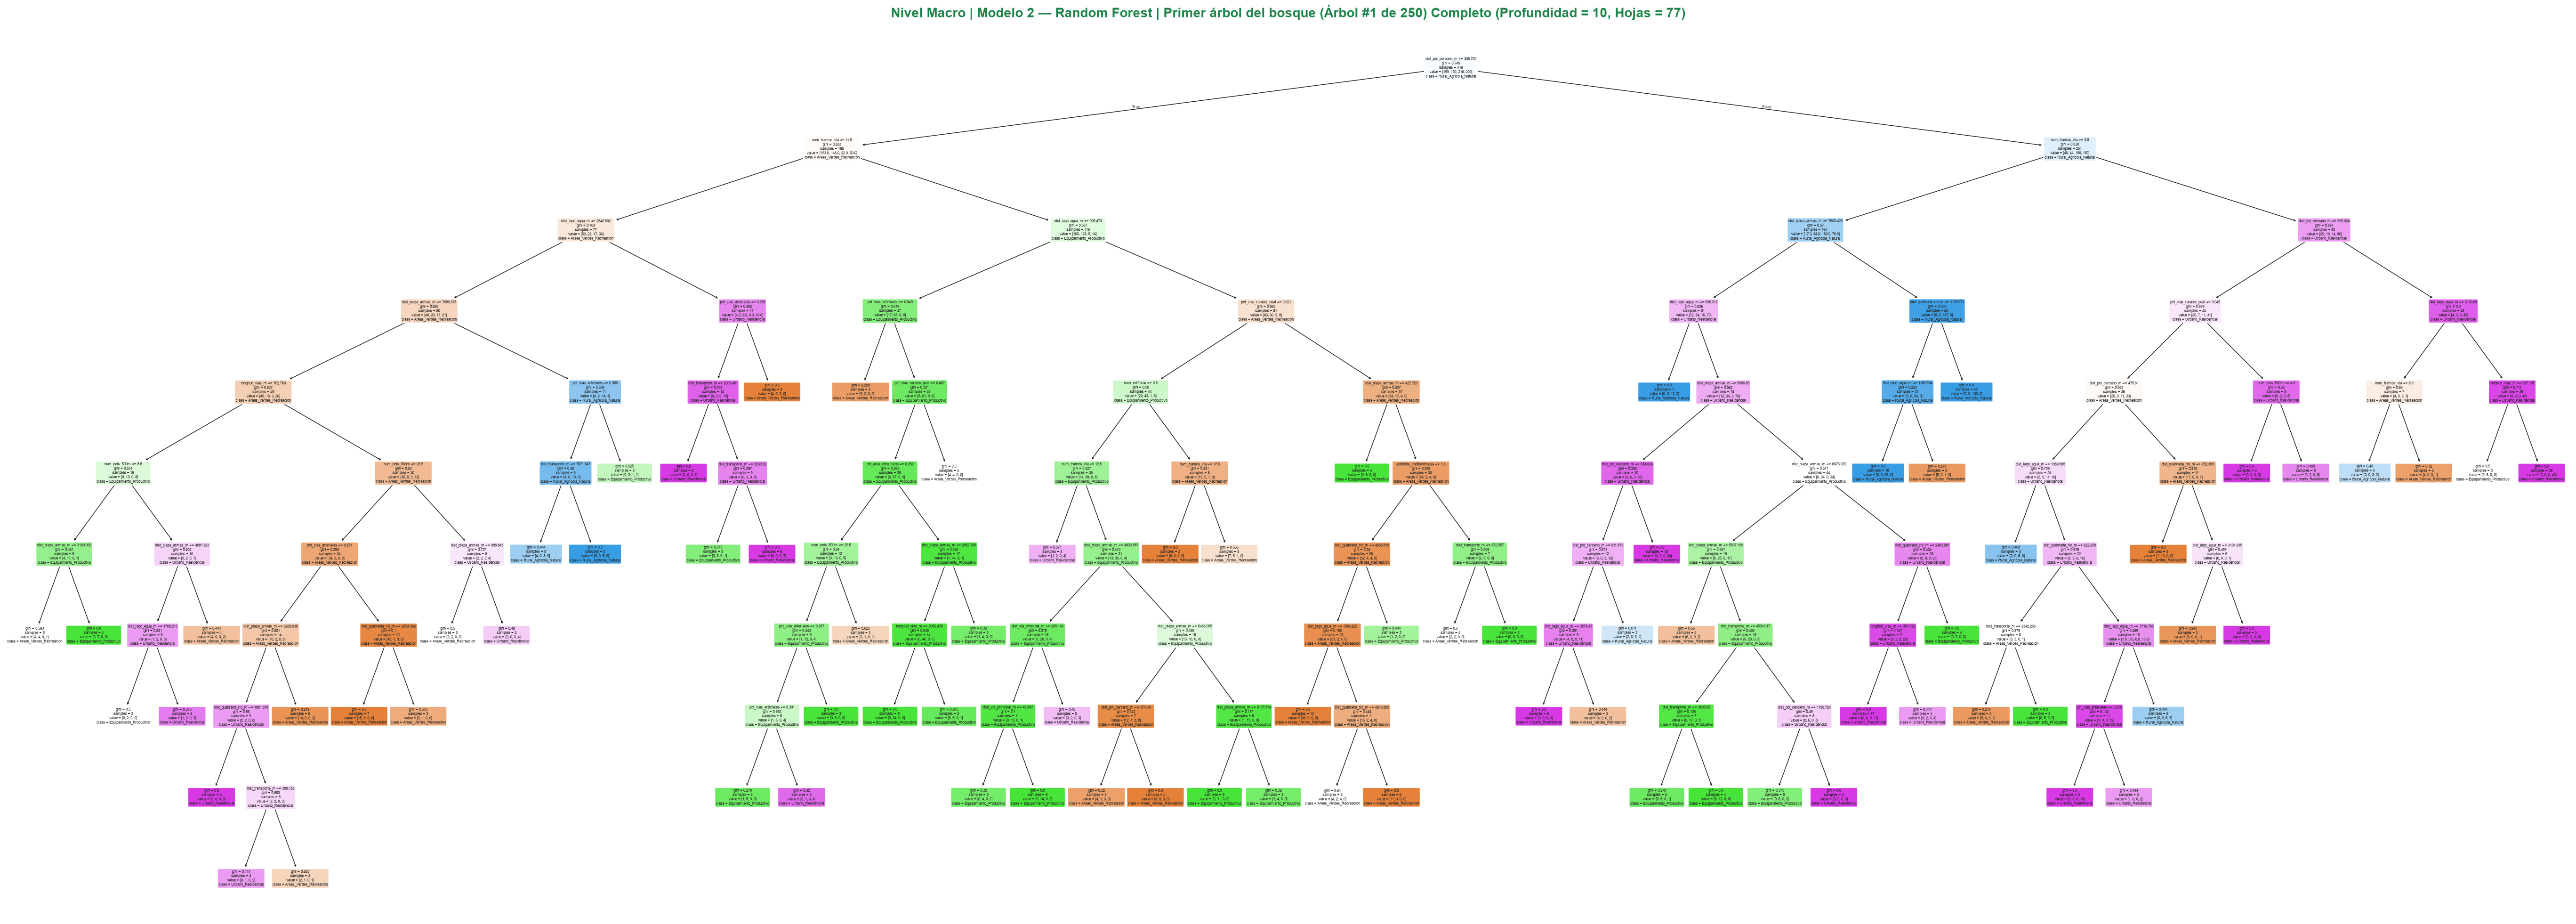

Figura guardada en: figures/03_arbol_rf_001_completo.png


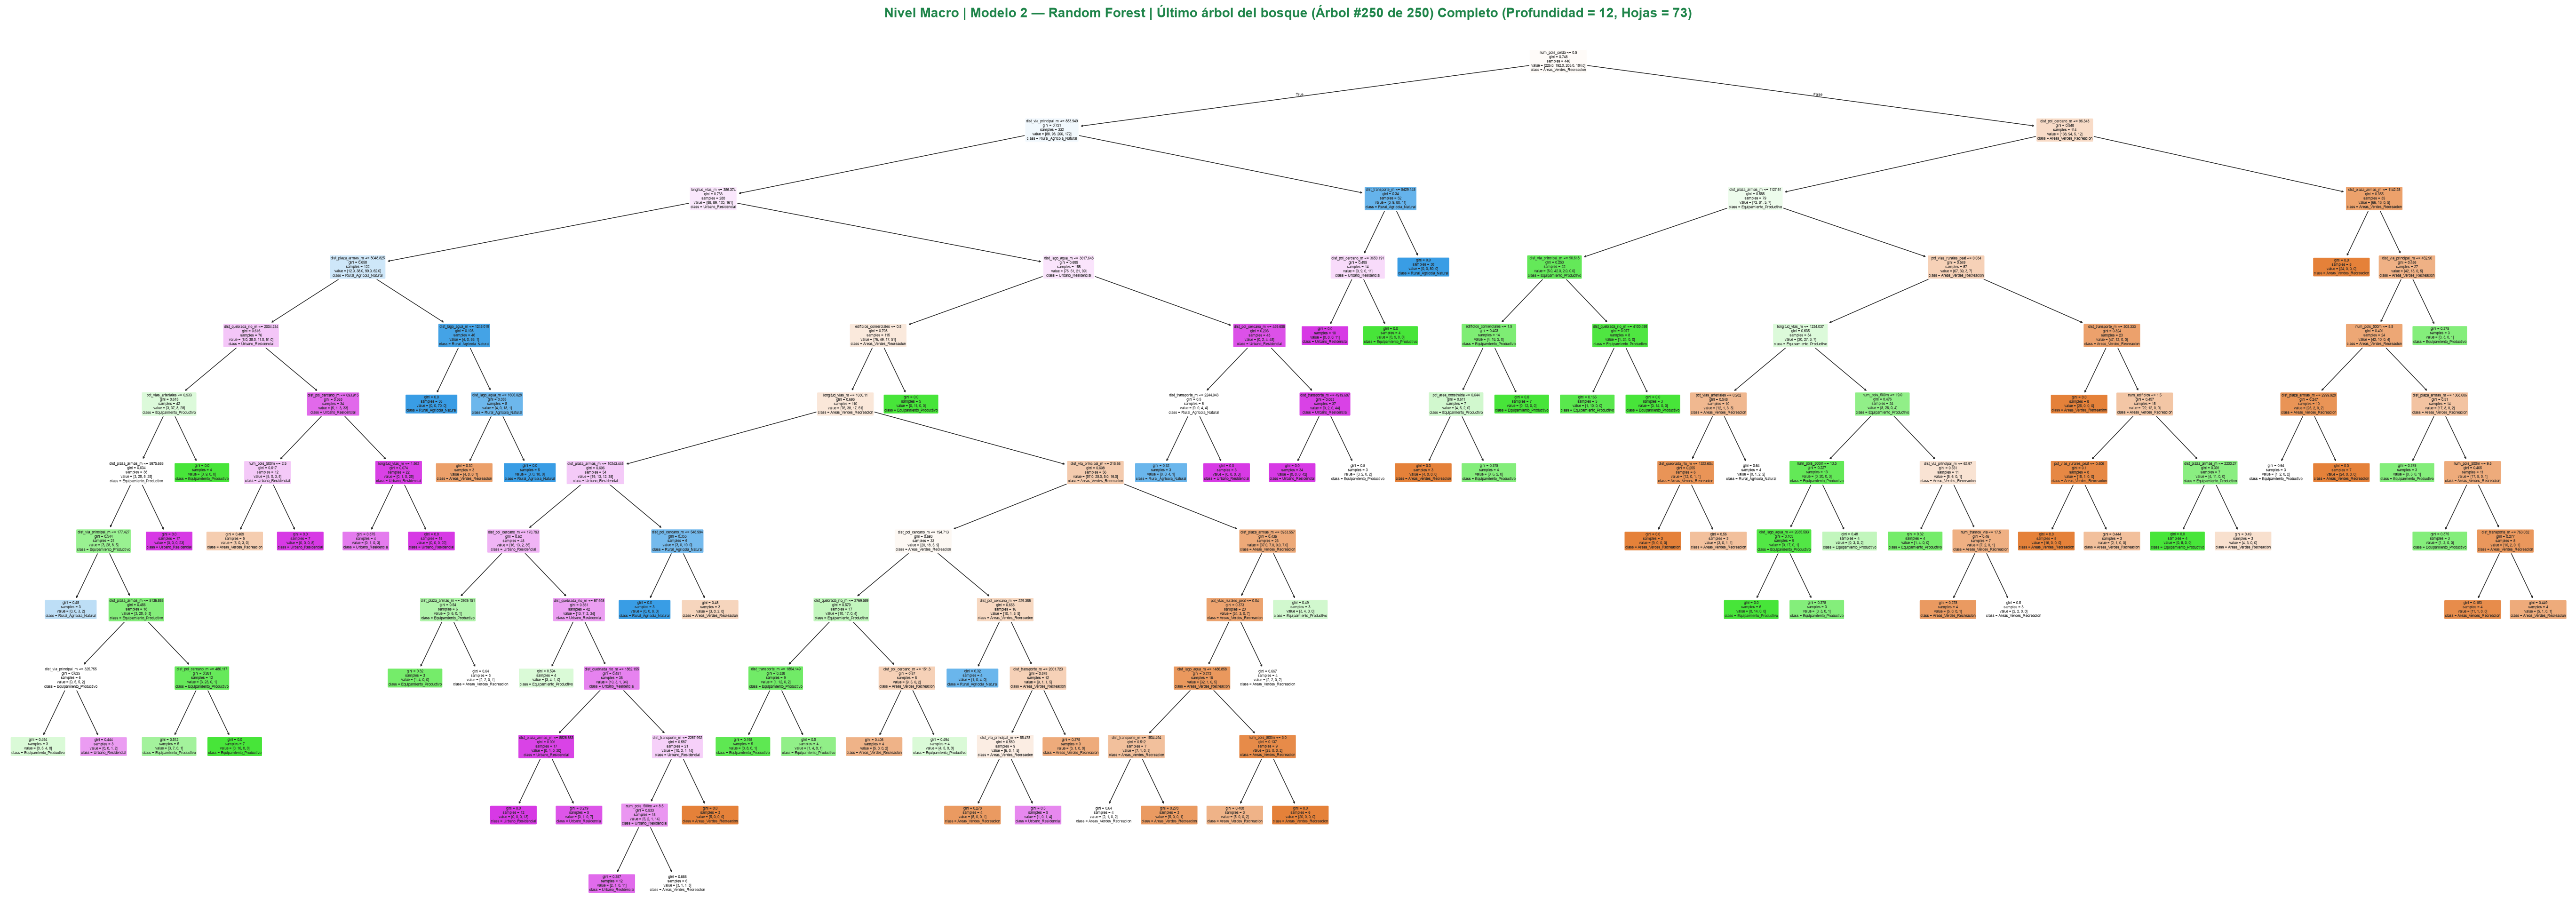

Figura guardada en: figures/03_arbol_rf_250_completo.png


In [11]:
rf_m = modelos_entrenados['Random Forest']

for idx_tree, fname, subtitulo in [
    (0,   "03_arbol_rf_001_completo.png", "Primer árbol del bosque (Árbol #1 de 250)"),
    (249, "03_arbol_rf_250_completo.png", "Último árbol del bosque (Árbol #250 de 250)")
]:
    est = rf_m.estimators_[idx_tree]
    fig, ax = plt.subplots(figsize=(50, 18))
    plot_tree(
        est,
        feature_names=FEATURES_MACRO,
        class_names=clases_nombres,
        filled=True, rounded=True, fontsize=5, ax=ax
    )
    ax.set_title(
        f"Nivel Macro | Modelo 2 — Random Forest | {subtitulo} Completo (Profundidad = {est.get_depth()}, Hojas = {est.get_n_leaves()})",
        fontsize=18, fontweight='bold', color='#1e8449', pad=14
    )
    plt.tight_layout()
    plt.savefig(DIR_FIGURES / fname, bbox_inches='tight', dpi=200)
    plt.show()
    print(f"Figura guardada en: figures/{fname}")

### 6.4 y 6.5. Modelos 3 y 4 — `XGBoost` y `LightGBM` Completos (Inicio y Ronda Final #200)

Mostramos los árboles reales completos (sin truncar ninguna hoja) para la clase `Urbano_Residencial` / `Areas_Verdes_Recreacion`, comparando el inicio del Boosting (ganancias grandes) frente a la **Ronda Final #200** (ajustes residuales finos al converger).

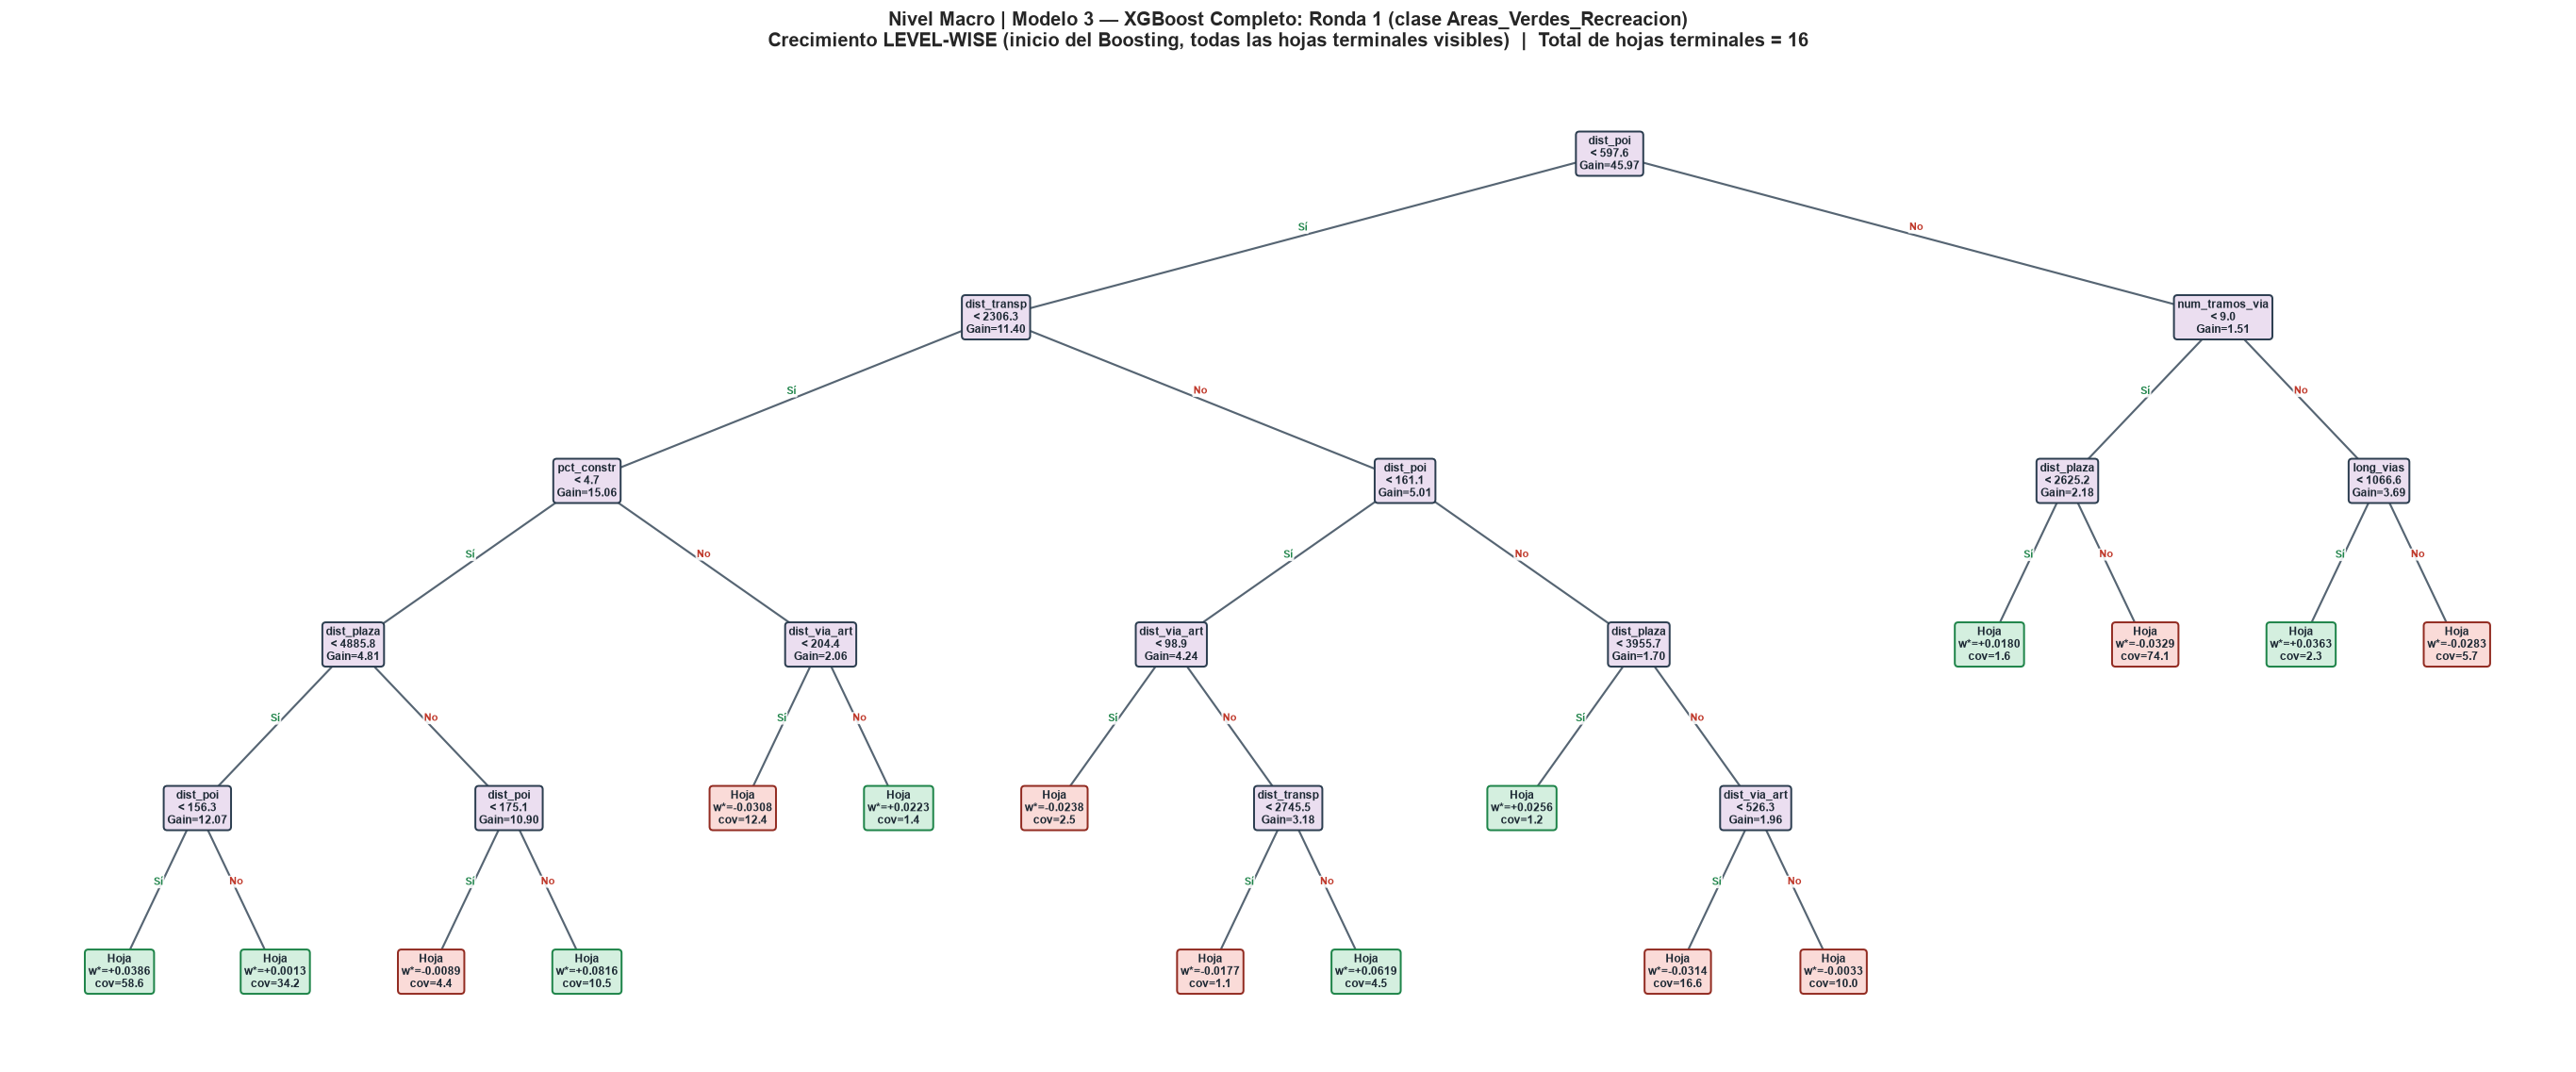

Figura guardada en: figures/03_arbol_xgboost_ronda1_completo.png


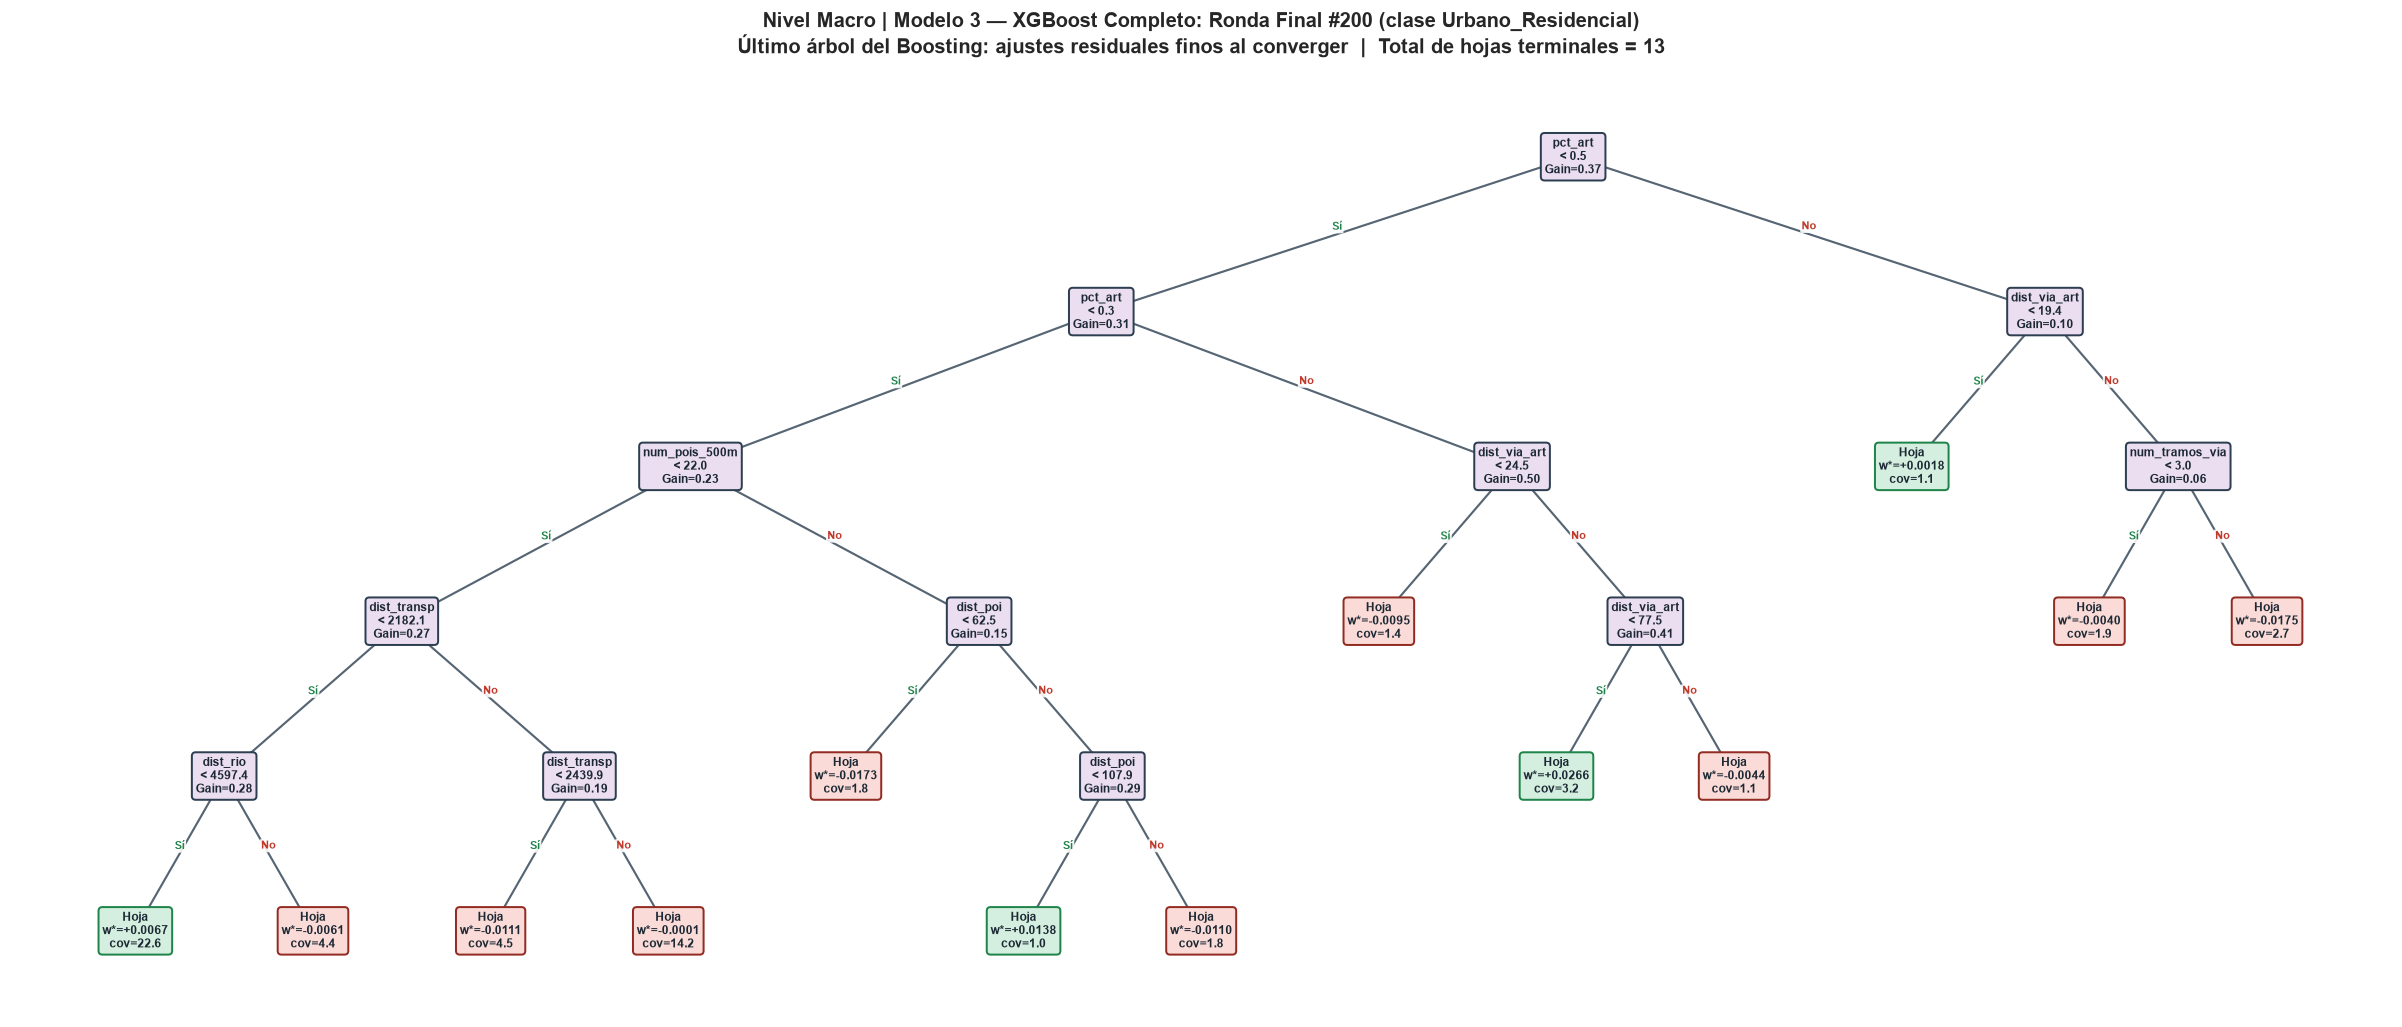

Figura guardada en: figures/03_arbol_xgboost_ronda200_completo.png


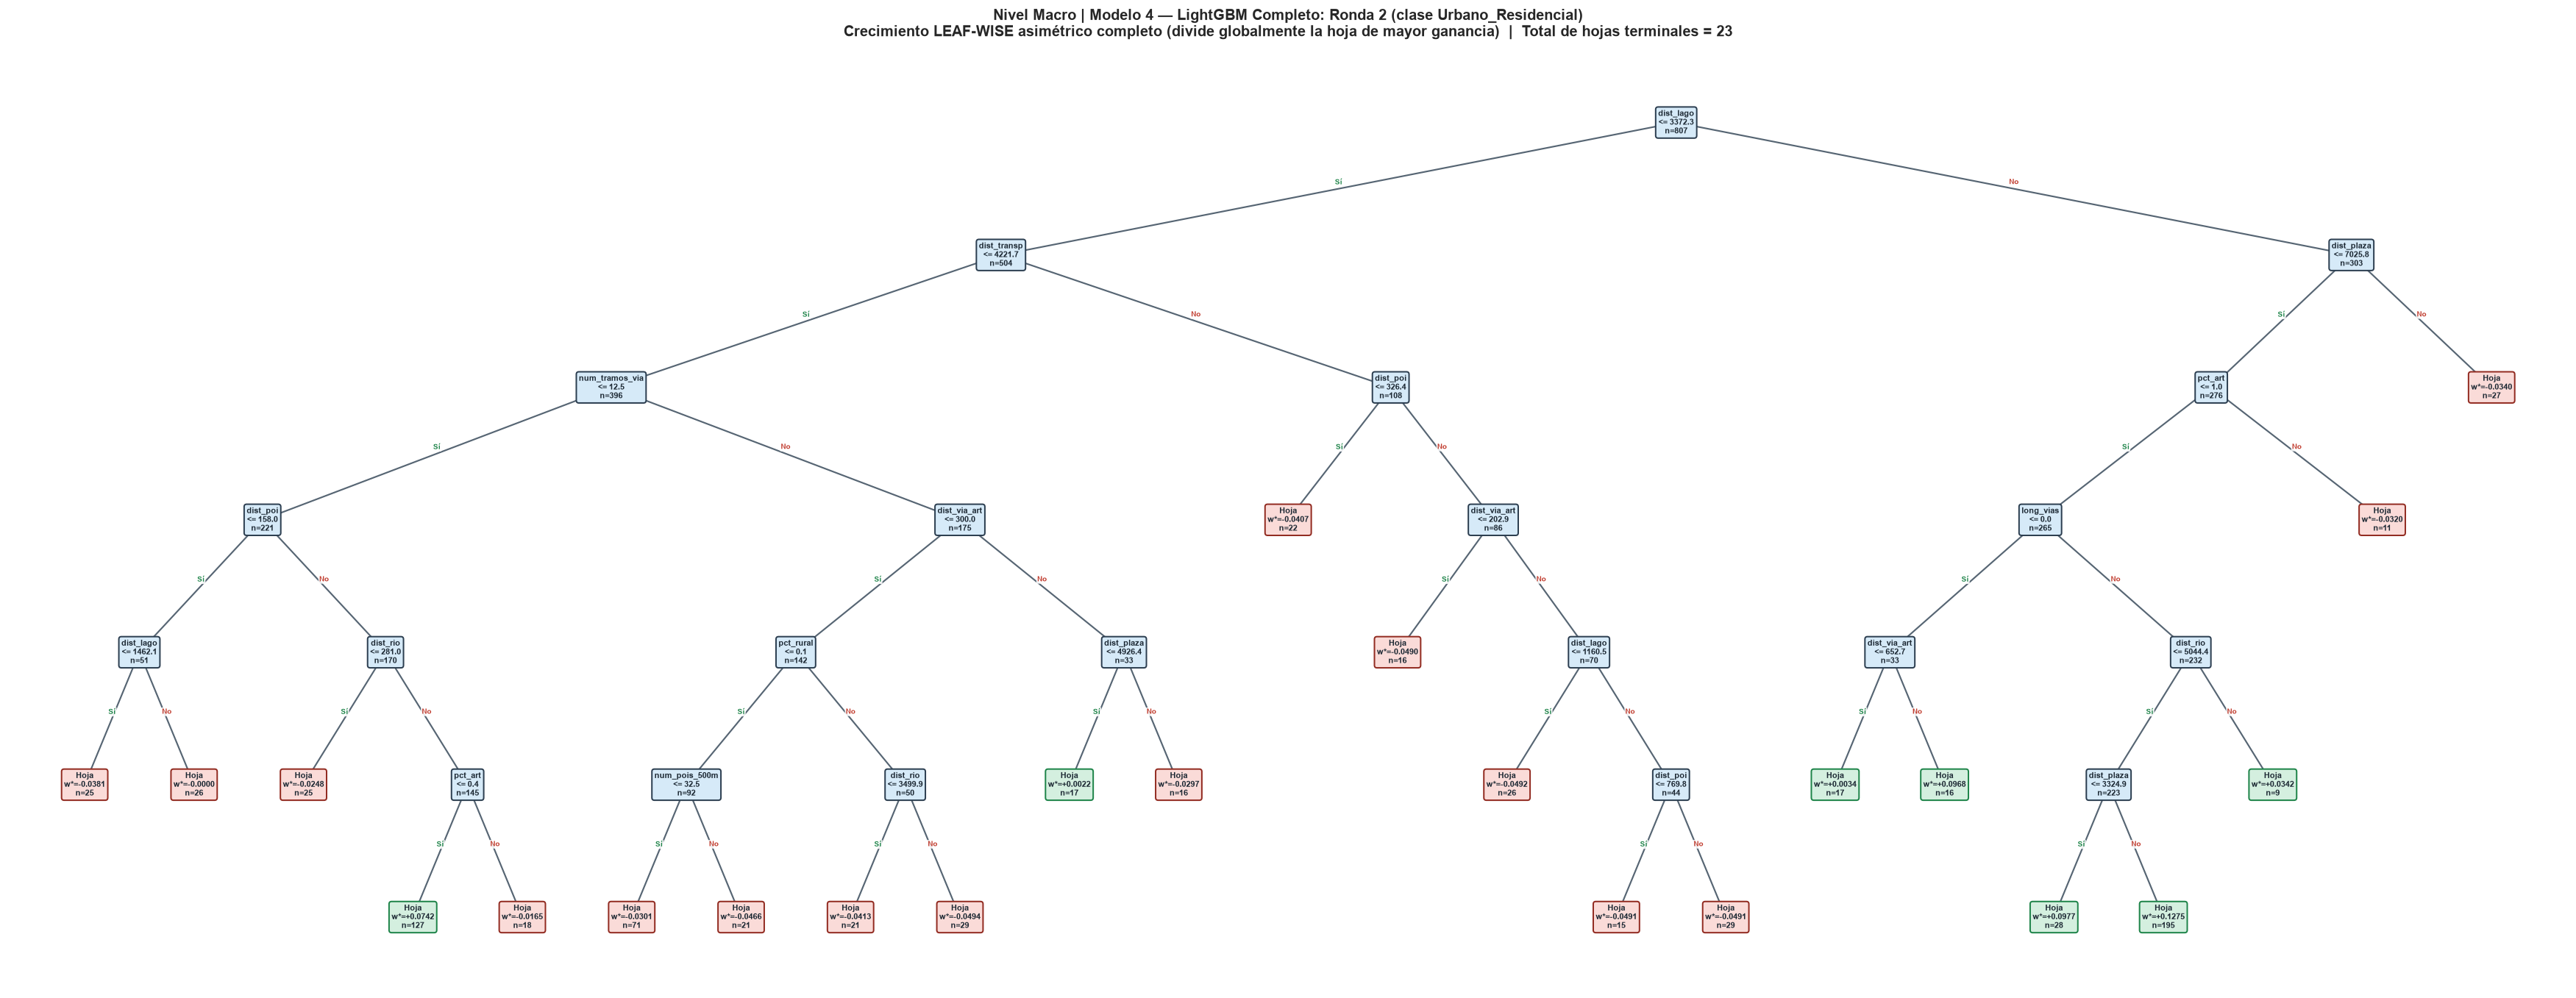

Figura guardada en: figures/03_arbol_lightgbm_ronda2_completo.png


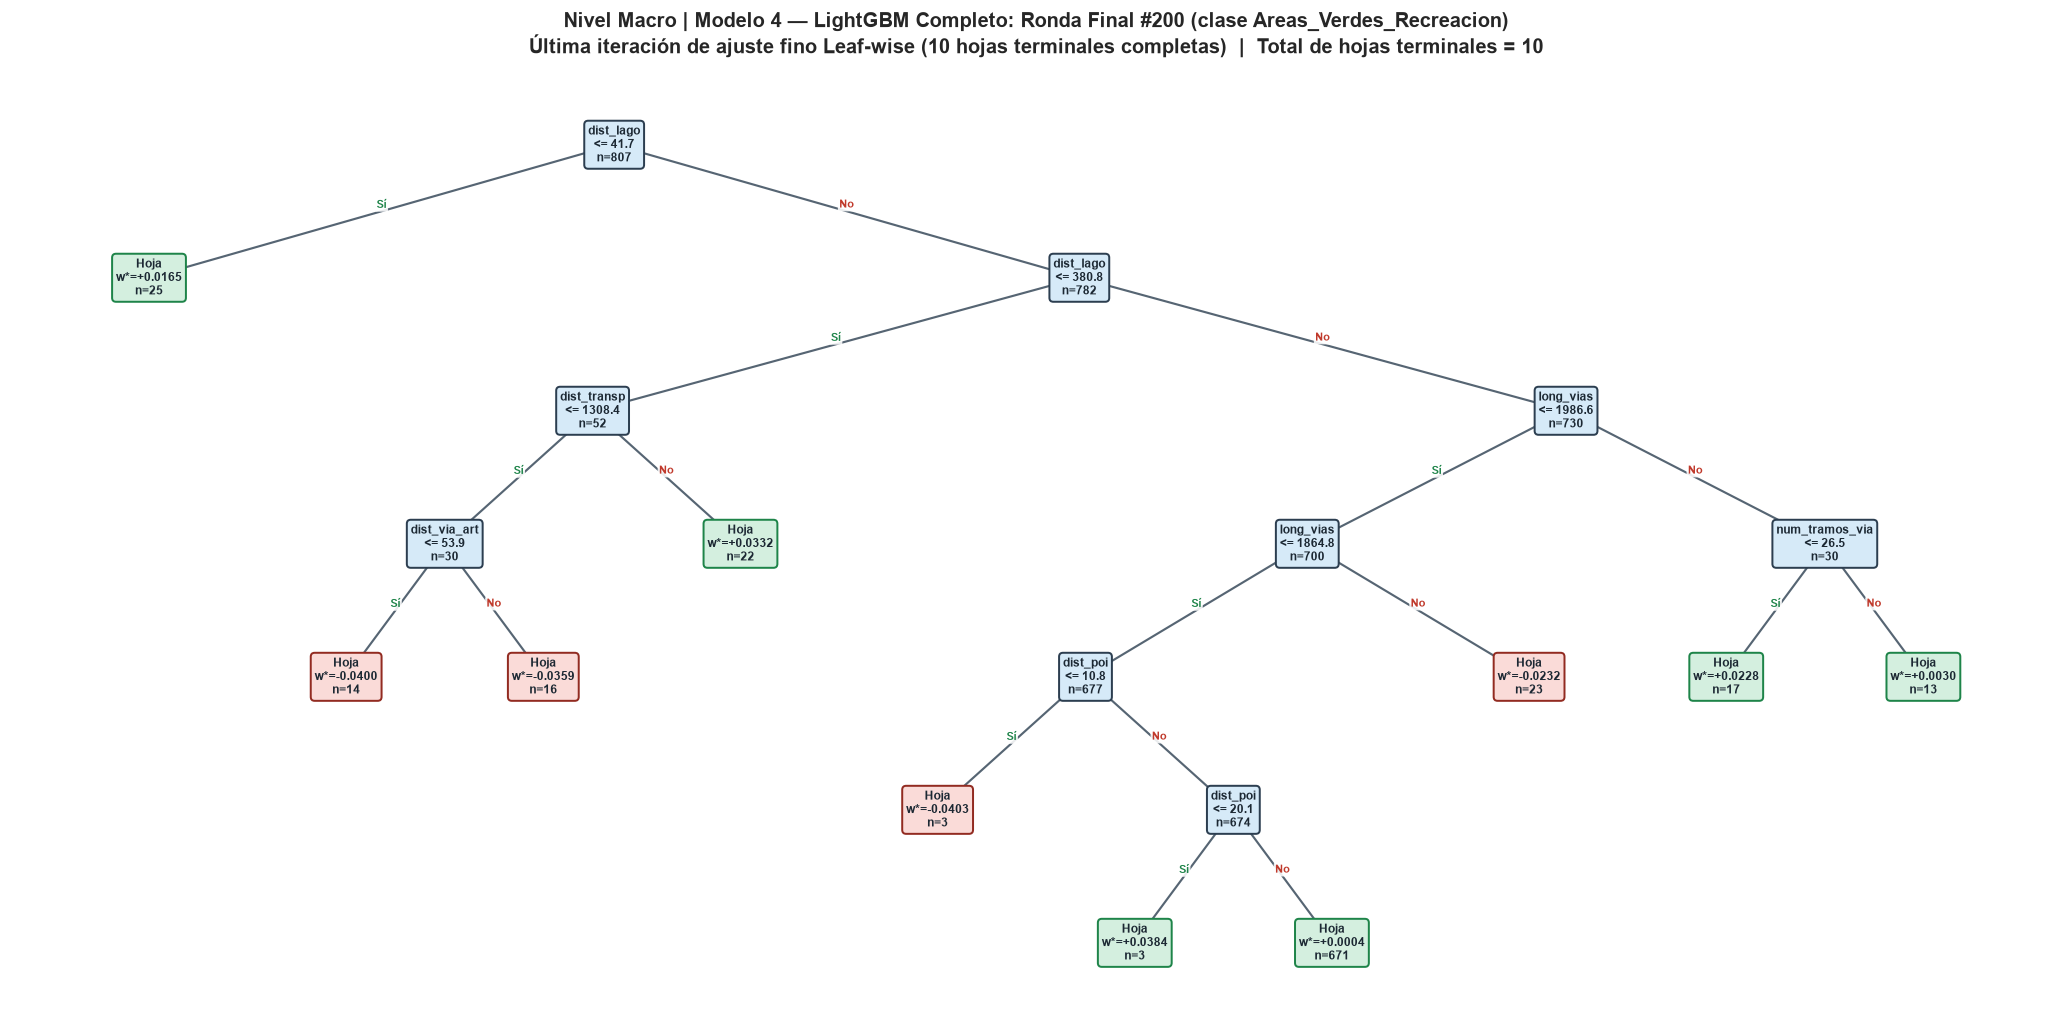

Figura guardada en: figures/03_arbol_lightgbm_ronda200_completo.png


In [12]:
def acortar_var_macro(s):
    return (
        str(s)
        .replace('dist_plaza_armas_m', 'dist_plaza')
        .replace('dist_lago_agua_m', 'dist_lago')
        .replace('dist_quebrada_rio_m', 'dist_rio')
        .replace('dist_via_principal_m', 'dist_via_art')
        .replace('dist_poi_cercano_m', 'dist_poi')
        .replace('dist_transporte_m', 'dist_transp')
        .replace('longitud_vias_m', 'long_vias')
        .replace('pct_vias_arteriales', 'pct_art')
        .replace('pct_vias_rurales_peat', 'pct_rural')
        .replace('pct_area_construida', 'pct_constr')
        .replace('edificios_residenciales', 'edif_res')
        .replace('edificios_comerciales', 'edif_com')
        .replace('edificios_institucionales', 'edif_inst')
    )

def extraer_xgb_completo(xgb_model, tree_idx):
    df_t = xgb_model.get_booster().trees_to_dataframe()
    sub = df_t[df_t['Tree'] == tree_idx].set_index('ID')
    root_id = f"{tree_idx}-0"

    def build(nid):
        row = sub.loc[nid]
        if row['Feature'] == 'Leaf':
            val = float(row['Gain'])
            lbl = f"Hoja\nw*={val:+.4f}\ncov={row['Cover']:.1f}"
            return {'label': lbl, 'is_leaf': True, 'val': val, 'left': None, 'right': None}
        lbl = f"{acortar_var_macro(row['Feature'])}\n< {float(row['Split']):.1f}\nGain={float(row['Gain']):.2f}"
        return {
            'label': lbl, 'is_leaf': False, 'val': 0.0,
            'left': build(row['Yes']),
            'right': build(row['No'])
        }
    return build(root_id)

def extraer_lgbm_completo(lgbm_model, tree_idx):
    df_t = lgbm_model.booster_.trees_to_dataframe()
    sub = df_t[df_t['tree_index'] == tree_idx].set_index('node_index')
    root_id = sub[sub['node_depth'] == 1].index[0]

    def build(nid):
        row = sub.loc[nid]
        if pd.isna(row['split_feature']):
            val = float(row['value'])
            lbl = f"Hoja\nw*={val:+.4f}\nn={int(row['count'])}"
            return {'label': lbl, 'is_leaf': True, 'val': val, 'left': None, 'right': None}
        lbl = f"{acortar_var_macro(row['split_feature'])}\n<= {float(row['threshold']):.1f}\nn={int(row['count'])}"
        return {
            'label': lbl, 'is_leaf': False, 'val': 0.0,
            'left': build(row['left_child']),
            'right': build(row['right_child'])
        }
    return build(root_id)

def dibujar_arbol_macro(root, titulo, subtitulo, color_nodo, fname, figsize=(24, 10.5), fontsize=7.8):
    coords = {}
    leaf_counter = [0]
    max_d = [0]

    def assign_pos(node, depth):
        max_d[0] = max(max_d[0], depth)
        if node['left'] is None and node['right'] is None:
            x = leaf_counter[0]
            leaf_counter[0] += 1
            coords[id(node)] = (x, -depth)
            return x
        xl = assign_pos(node['left'], depth + 1)
        xr = assign_pos(node['right'], depth + 1)
        x = (xl + xr) / 2.0
        coords[id(node)] = (x, -depth)
        return x

    assign_pos(root, 0)

    fig, ax = plt.subplots(figsize=figsize)
    def draw(node):
        x, y = coords[id(node)]
        for side, child, edge_lbl in [('L', node['left'], 'Sí'), ('R', node['right'], 'No')]:
            if child is not None:
                cx, cy = coords[id(child)]
                ax.plot([x, cx], [y, cy], color='#566573', linewidth=1.4, zorder=1)
                mx, my = (x + cx) / 2.0, (y + cy) / 2.0
                ax.text(mx, my + 0.05, edge_lbl, fontsize=max(fontsize - 0.5, 6.5), fontweight='bold',
                        color='#1e8449' if side == 'L' else '#c0392b', ha='center', va='center',
                        bbox=dict(boxstyle='round,pad=0.12', facecolor='white', edgecolor='none', alpha=0.88))
                draw(child)

        if node['is_leaf']:
            fc = '#d4efdf' if node['val'] >= 0 else '#fadbd8'
            ec = '#1e8449' if node['val'] >= 0 else '#922b21'
        else:
            fc = color_nodo
            ec = '#2c3e50'
        ax.text(
            x, y, node['label'], ha='center', va='center', fontsize=fontsize, fontweight='bold', color='#1c2833',
            bbox=dict(boxstyle='round,pad=0.32', facecolor=fc, edgecolor=ec, linewidth=1.3), zorder=3
        )

    draw(root)
    ax.set_xlim(-0.7, leaf_counter[0] - 0.3)
    ax.set_ylim(-max_d[0] - 0.55, 0.55)
    ax.axis('off')
    ax.set_title(f"{titulo}\n{subtitulo}  |  Total de hojas terminales = {leaf_counter[0]}",
                 fontsize=13, fontweight='bold', pad=12)
    plt.tight_layout()
    plt.savefig(DIR_FIGURES / fname, bbox_inches='tight', dpi=250)
    plt.show()
    print(f"Figura guardada en: figures/{fname}")

# --- MODELO 3: XGBOOST COMPLETO (RONDA 1 Y RONDA FINAL #200) ---
xgb_m = modelos_entrenados['XGBoost']
dibujar_arbol_macro(
    extraer_xgb_completo(xgb_m, tree_idx=0),
    "Nivel Macro | Modelo 3 — XGBoost Completo: Ronda 1 (clase Areas_Verdes_Recreacion)",
    "Crecimiento LEVEL-WISE (inicio del Boosting, todas las hojas terminales visibles)",
    color_nodo='#ebdef0', fname="03_arbol_xgboost_ronda1_completo.png", figsize=(25, 10.5), fontsize=7.6
)
dibujar_arbol_macro(
    extraer_xgb_completo(xgb_m, tree_idx=799),
    "Nivel Macro | Modelo 3 — XGBoost Completo: Ronda Final #200 (clase Urbano_Residencial)",
    "Último árbol del Boosting: ajustes residuales finos al converger",
    color_nodo='#ebdef0', fname="03_arbol_xgboost_ronda200_completo.png", figsize=(22, 9.5), fontsize=7.8
)

# --- MODELO 4: LIGHTGBM COMPLETO (RONDA 2 Y RONDA FINAL #200) ---
lgbm_m = modelos_entrenados['LightGBM']
dibujar_arbol_macro(
    extraer_lgbm_completo(lgbm_m, tree_idx=7),
    "Nivel Macro | Modelo 4 — LightGBM Completo: Ronda 2 (clase Urbano_Residencial)",
    "Crecimiento LEAF-WISE asimétrico completo (divide globalmente la hoja de mayor ganancia)",
    color_nodo='#d6eaf8', fname="03_arbol_lightgbm_ronda2_completo.png", figsize=(32, 12.5), fontsize=7.0
)
dibujar_arbol_macro(
    extraer_lgbm_completo(lgbm_m, tree_idx=796),
    "Nivel Macro | Modelo 4 — LightGBM Completo: Ronda Final #200 (clase Areas_Verdes_Recreacion)",
    "Última iteración de ajuste fino Leaf-wise (10 hojas terminales completas)",
    color_nodo='#d6eaf8', fname="03_arbol_lightgbm_ronda200_completo.png", figsize=(19, 9.5), fontsize=8.0
)

## 7. Matrices de Confusión (4×4, Test = 202 celdas) e Importancia de Variables

En la matriz de confusión **4×4**:
* La **diagonal principal** reúne las celdas correctamente zonificadas (`Real == Predicho`).
* Las celdas fuera de la diagonal muestran las confusiones espaciales naturales de una ciudad (por ejemplo, celdas en la frontera entre `Urbano_Residencial` y `Areas_Verdes_Recreacion` o `Equipamiento_Productivo`).
* Observa cómo los ensambles (**Random Forest**, **XGBoost** y **LightGBM**) concentran mucho mayor peso en la diagonal que los árboles individuales (`Gini` / `Entropía`).

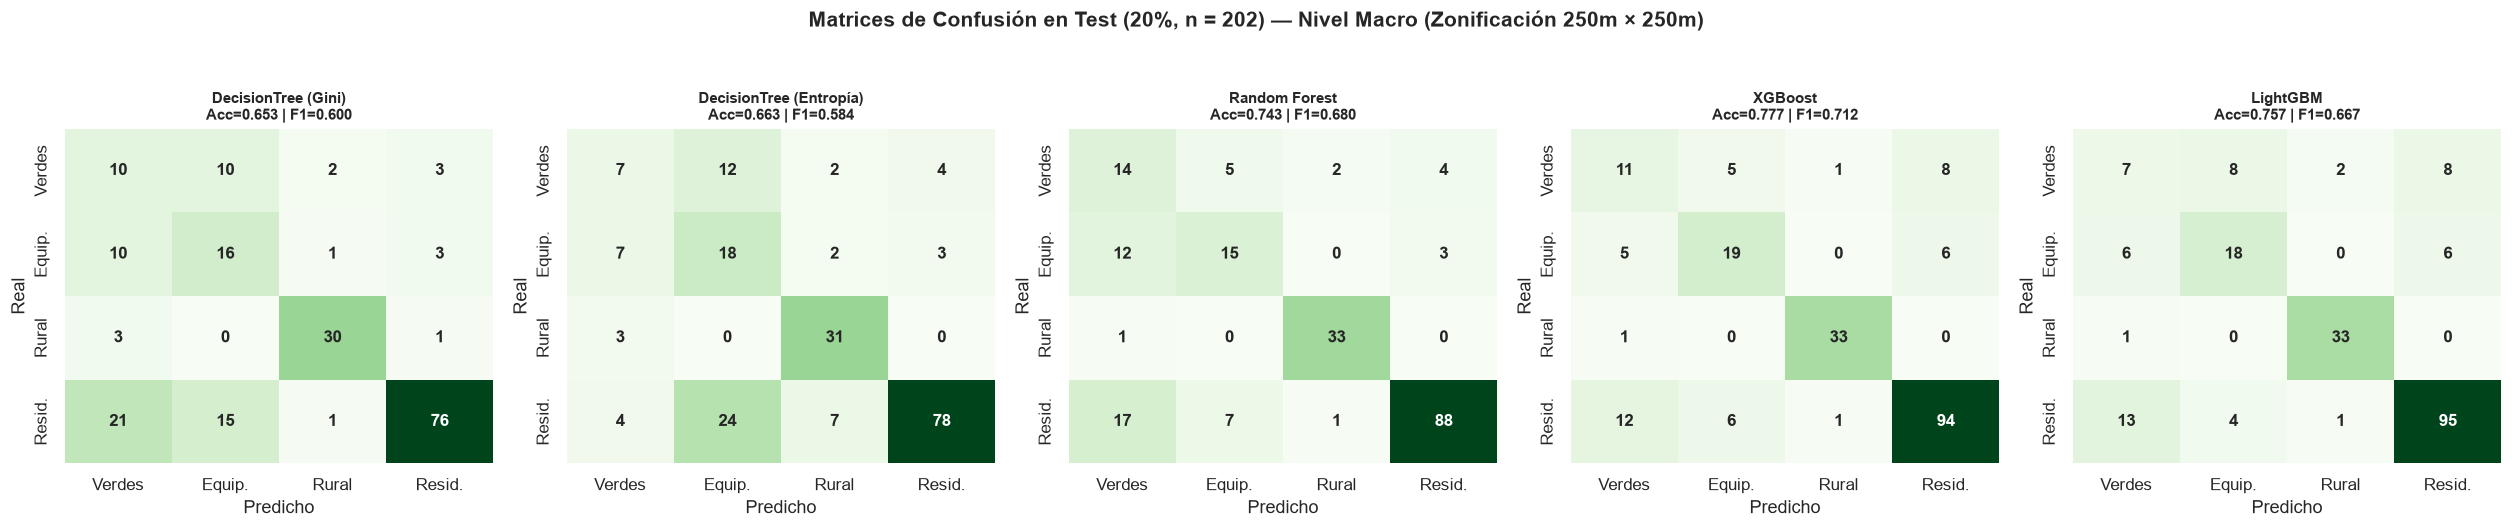

Figura guardada en: figures/03_matrices_confusion_macro.png


In [13]:
fig, axes = plt.subplots(1, 5, figsize=(23, 4.6))
etiquetas_cortas = ['Verdes', 'Equip.', 'Rural', 'Resid.']

for ax, (nombre, y_pred) in zip(axes, predicciones_test.items()):
    cm = confusion_matrix(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    f1m = f1_score(y_test, y_pred, average='macro')
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
                annot_kws={'size': 11, 'weight': 'bold'},
                xticklabels=etiquetas_cortas, yticklabels=etiquetas_cortas, ax=ax)
    ax.set_title(f"{nombre}\nAcc={acc:.3f} | F1={f1m:.3f}", fontsize=10, fontweight='bold')
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

plt.suptitle("Matrices de Confusión en Test (20%, n = 202) — Nivel Macro (Zonificación 250m × 250m)",
             fontsize=13.5, fontweight='bold', y=1.04)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "03_matrices_confusion_macro.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/03_matrices_confusion_macro.png")

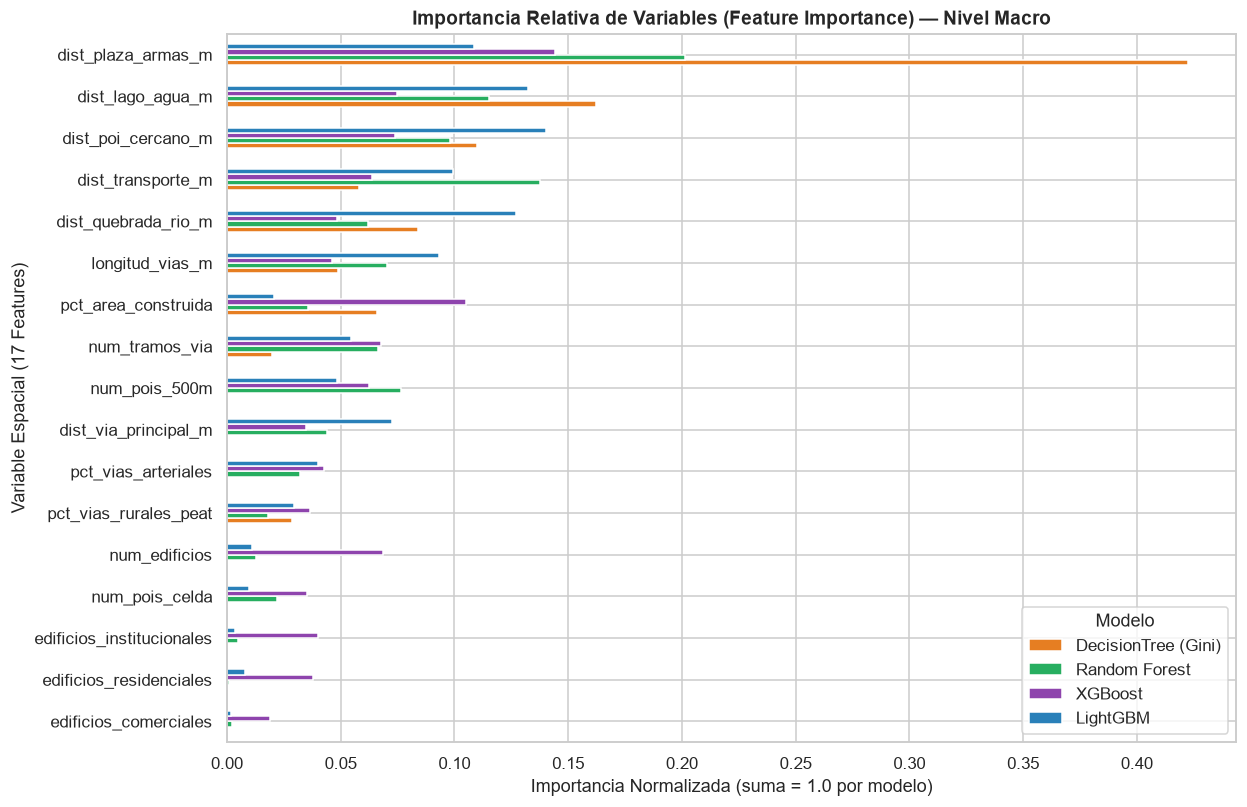

Figura guardada en: figures/03_feature_importance_macro.png


In [14]:
imp_df = pd.DataFrame(index=FEATURES_MACRO)
for nombre in ['DecisionTree (Gini)', 'Random Forest', 'XGBoost', 'LightGBM']:
    imp = modelos_entrenados[nombre].feature_importances_
    imp_df[nombre] = imp / (imp.sum() + 1e-9)

imp_df['Promedio'] = imp_df.mean(axis=1)
imp_df = imp_df.sort_values('Promedio', ascending=True)

imp_df.drop(columns=['Promedio']).plot(
    kind='barh', figsize=(11.5, 7.5),
    color=['#e67e22', '#27ae60', '#8e44ad', '#2980b9'], edgecolor='white'
)
plt.title("Importancia Relativa de Variables (Feature Importance) — Nivel Macro", fontsize=12.5, fontweight='bold')
plt.xlabel("Importancia Normalizada (suma = 1.0 por modelo)")
plt.ylabel("Variable Espacial (17 Features)")
plt.legend(title="Modelo", loc="lower right")
plt.tight_layout()
plt.savefig(DIR_FIGURES / "03_feature_importance_macro.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/03_feature_importance_macro.png")

## 8. Predicción de las 1,091 Celdas Sin Zonificar y Mapa Interactivo Mejorado de Puno

Reentrenamos el modelo ganador del Nivel Macro (**Random Forest**) con el **100% de las `1,009` celdas verificadas** y predecimos la zonificación de las **`1,091` celdas activas** sin etiqueta de uso de suelo en OSM.  
En el mapa interactivo distinguimos visualmente las celdas **Verificadas OSM (borde sólido, mayor opacidad)** de las **Predichas por ML (borde punteado)**, e incluimos popups enriquecidos, pantalla completa, minimapa y leyenda ejecutiva.

In [15]:
nombre_ganador_macro = df_resultados_macro.iloc[0]['Modelo']
cv_f1_ganador_macro = df_resultados_macro.iloc[0]['CV-5 F1 (Macro)']
modelo_ganador_macro = crear_modelos()[nombre_ganador_macro]
print(f"Modelo ganador del Nivel Macro (por CV-5 F1 Macro): {nombre_ganador_macro} ({cv_f1_ganador_macro:.4f})")

if nombre_ganador_macro == 'XGBoost':
    modelo_ganador_macro.fit(X, y, sample_weight=compute_sample_weight('balanced', y))
else:
    modelo_ganador_macro.fit(X, y)

mask_unlabeled = grid_activas['zona_macro'].isnull()
X_unlabeled = grid_activas.loc[mask_unlabeled, FEATURES_MACRO]
preds_unlabeled = le.inverse_transform(modelo_ganador_macro.predict(X_unlabeled))

grid_activas['origen_etiqueta'] = np.where(mask_unlabeled, 'Predicho (ML)', 'Verificado (OSM)')
grid_activas['zona_final'] = grid_activas['zona_macro'].copy()
grid_activas.loc[mask_unlabeled, 'zona_final'] = preds_unlabeled

print("\nResumen final de las 2,100 celdas activas del Distrito de Puno:")
display(pd.crosstab(grid_activas['zona_final'], grid_activas['origen_etiqueta'], margins=True))

grid_final_wgs = grid_activas.to_crs("EPSG:4326")
grid_final_wgs.to_file(DIR_DATA_PUNO / "puno_zonificacion_macro.geojson", driver="GeoJSON")
print("Guardado exitosamente: data_puno/puno_zonificacion_macro.geojson")

Modelo ganador del Nivel Macro (por CV-5 F1 Macro): Random Forest (0.6980)

Resumen final de las 2,100 celdas activas del Distrito de Puno:


origen_etiqueta,Predicho (ML),Verificado (OSM),All
zona_final,,,
Areas_Verdes_Recreacion,10,127,137
Equipamiento_Productivo,45,149,194
Rural_Agricola_Natural,632,167,799
Urbano_Residencial,404,566,970
All,1091,1009,2100


Guardado exitosamente: data_puno/puno_zonificacion_macro.geojson


In [17]:
# Mapa Interactivo Folium Mejorado — Nivel Macro (Zonificación Urbana y Rural de Puno)
colores_macro = {
    'Urbano_Residencial': '#2e86de',       # Azul
    'Rural_Agricola_Natural': '#d4ac0d',   # Ocre / Amarillo
    'Equipamiento_Productivo': '#8e44ad',  # Morado
    'Areas_Verdes_Recreacion': '#27ae60'   # Verde
}

m_macro = folium.Map(location=[-15.8402, -70.0280], zoom_start=13, tiles="OpenStreetMap")
Fullscreen(position='topright', title='Pantalla completa', title_cancel='Salir').add_to(m_macro)
MiniMap(toggle_display=True, minimized=True).add_to(m_macro)

folium.GeoJson(
    gdf_boundary,
    name="Límite Distrito de Puno",
    style_function=lambda x: {'fillColor': 'none', 'color': '#2c3e50', 'weight': 2.2, 'dashArray': '6, 4'}
).add_to(m_macro)

cols_viz = [
    'cell_id', 'zona_final', 'origen_etiqueta', 'longitud_vias_m',
    'num_edificios', 'num_pois_500m', 'dist_plaza_armas_m', 'dist_lago_agua_m', 'geometry'
]
grid_viz = grid_final_wgs[cols_viz].copy()
grid_viz['longitud_vias_m'] = grid_viz['longitud_vias_m'].round(1)
grid_viz['num_edificios'] = grid_viz['num_edificios'].astype(int)
grid_viz['num_pois_500m'] = grid_viz['num_pois_500m'].astype(int)
grid_viz['dist_plaza_armas_m'] = grid_viz['dist_plaza_armas_m'].round(0).astype(int)
grid_viz['dist_lago_agua_m'] = grid_viz['dist_lago_agua_m'].round(0).astype(int)

for zona, color in colores_macro.items():
    sub = grid_viz[grid_viz['zona_final'] == zona]
    n_ver = int((sub['origen_etiqueta'] == 'Verificado (OSM)').sum())
    n_pre = int((sub['origen_etiqueta'] == 'Predicho (ML)').sum())

    fg = folium.FeatureGroup(name=f"{zona} ({len(sub)}: {n_ver} verif. + {n_pre} pred.)", show=True)
    folium.GeoJson(
        sub,
        style_function=lambda feat, c=color: {
            'fillColor': c,
            'color': '#1c2833' if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else c,
            'weight': 0.9 if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else 0.6,
            'dashArray': None if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else '3, 3',
            'fillOpacity': 0.62 if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else 0.40
        },
        highlight_function=lambda feat: {'weight': 2.5, 'color': '#e74c3c', 'fillOpacity': 0.8},
        tooltip=folium.GeoJsonTooltip(
            fields=['zona_final', 'origen_etiqueta', 'longitud_vias_m', 'num_edificios'],
            aliases=['Zonificación:', 'Origen:', 'Long. Vías (m):', 'N° Edificios:'],
            localize=True
        ),
        popup=folium.GeoJsonPopup(
            fields=['cell_id', 'zona_final', 'origen_etiqueta', 'longitud_vias_m',
                    'num_edificios', 'num_pois_500m', 'dist_plaza_armas_m', 'dist_lago_agua_m'],
            aliases=['Celda ID:', 'Zonificación:', 'Origen:', 'Long. Vías (m):',
                     'Edificios (Micro):', 'POIs en 500m:', 'Dist. Plaza Armas (m):', 'Dist. Lago Titicaca (m):'],
            localize=True, max_width=300
        )
    ).add_to(fg)
    fg.add_to(m_macro)

folium.Marker(
    location=[-15.8402, -70.0280],
    tooltip="Plaza de Armas de Puno (centro de referencia espacial)",
    icon=folium.Icon(color='red', icon='star')
).add_to(m_macro)

leyenda_macro_html = f'''
<div style="position: fixed; bottom: 25px; left: 25px; z-index: 9999; background: rgba(255,255,255,0.96);
            padding: 12px 15px; border: 1.5px solid #2c3e50; border-radius: 8px; font-size: 12px;
            box-shadow: 0 3px 10px rgba(0,0,0,0.22); line-height: 1.5; max-width: 280px;">
  <div style="font-weight: bold; font-size: 13px; color: #1c2833; border-bottom: 1px solid #d5d8dc; padding-bottom: 4px; margin-bottom: 6px;">
    Nivel Macro — Zonificación (250m × 250m)
  </div>
  <b>Zonas (2,100 celdas activas):</b><br>
  <span style="color:#2e86de; font-size:14px;">■</span> Urbano Residencial (970)<br>
  <span style="color:#d4ac0d; font-size:14px;">■</span> Rural / Agrícola / Natural (799)<br>
  <span style="color:#8e44ad; font-size:14px;">■</span> Equipamiento / Productivo (194)<br>
  <span style="color:#27ae60; font-size:14px;">■</span> Áreas Verdes / Recreación (137)<br>
  <hr style="margin: 6px 0; border: none; border-top: 1px solid #eaecee;">
  <b>Origen de etiqueta:</b><br>
  <span style="display:inline-block; width:12px; height:10px; border:1.5px solid #1c2833; background:#aaa; vertical-align:middle;"></span> Verificado OSM (1,009)<br>
  <span style="display:inline-block; width:12px; height:10px; border:1.5px dashed #555; background:#ddd; vertical-align:middle;"></span> Predicho ML — {nombre_ganador_macro} (1,091)<br>
  <span style="color:#566573; font-size:11px;">CV-5 F1 Macro: <b>{cv_f1_ganador_macro:.4f}</b> | Clic en celda para detalles</span>
</div>
'''
m_macro.get_root().html.add_child(folium.Element(leyenda_macro_html))
folium.LayerControl(collapsed=False).add_to(m_macro)

ruta_html_macro = DIR_DATA_PUNO / "mapa_macro_zonificacion.html"
m_macro.save(ruta_html_macro)
print(f"Mapa interactivo Nivel Macro guardado en: {ruta_html_macro.resolve()}")
m_macro

Mapa interactivo Nivel Macro guardado en: C:\Users\ronim\OneDrive\Documents\Zonas_Puno\data_puno\mapa_macro_zonificacion.html
